# SportSnap: Phân loại Môn Thể thao qua Hình ảnh bằng CNN (Transfer Learning)

**Đề tài số 16 — Thị giác máy tính (IUH)**
GVHD: Lê Thị Vĩnh Thanh

**Mục tiêu:**
1. Xây dựng mô hình phân loại môn thể thao qua ảnh (15–20 môn phổ biến), Accuracy ≥ 0.88 trên tập test.
2. Dùng bộ dữ liệu Sports Image Classification (Kaggle, công khai).
3. So sánh ≥ 3 kiến trúc: **CNN từ đầu (baseline)**, **MobileNetV2** (transfer learning), **ResNet** (transfer learning).
4. Phân tích Grad-CAM để xác định vùng ảnh quan trọng (đặc trưng thị giác: màu sân, trang phục, dụng cụ...) đóng góp vào quyết định phân loại.

**Bộ dữ liệu:** [Sports Image Classification — Kaggle](https://www.kaggle.com/code/prathmesh284/image-classification-sports/input?select=valid)
(cấu trúc thư mục dạng `train/ valid(hoặc test)/` mỗi thư mục con là 1 lớp môn thể thao)

> **Lưu ý:** Notebook này được thiết kế để chạy trên **Kaggle Notebook**, **Google Colab** hoặc **máy cục bộ (Windows/Linux)**. Trên Kaggle, chỉ cần "Add Data" bộ dữ liệu trên, dữ liệu sẽ nằm ở `/kaggle/input/...`. Trên Colab, tải dữ liệu bằng Kaggle API rồi chỉnh biến `DATA_ROOT` bên dưới.
> Vì Kaggle không có sẵn kiến trúc "ResNet18" trong `tf.keras.applications`, nhóm dùng **ResNet50** (Keras) làm đại diện họ ResNet — có thể đổi sang `torchvision.models.resnet18` (PyTorch) nếu muốn bám sát đúng ResNet18.

---
### Các cải tiến & phần gộp (từ `SportSnap_Training_Optimized` + `detainhom_bosung`)
1. **Hàm huấn luyện dùng chung** `train_transfer_model()` (head → fine-tune), thay cho 2 cell lặp code; dùng lại được cho K-Fold và Multi-seed.
2. **Label smoothing 0.1** (loss `CategoricalCrossentropy`) – giảm quá tự tin, giúp chịu nhiễu nhãn (ví dụ `figure skating pairs` ↔ `women`).
3. **Cosine LR decay** ở giai đoạn fine-tune (thay cho ReduceLROnPlateau), và **EarlyStopping/Checkpoint theo `val_loss`** (val chỉ 100 ảnh nên `val_accuracy` bão hòa ở 1.0, chọn epoch theo accuracy gần như ngẫu nhiên).
4. **CNN từ đầu** thêm BatchNorm + block conv kép → baseline mạnh hơn, so sánh công bằng hơn.
5. **Test-Time Augmentation (lật ngang)** khi đánh giá + ensemble có trọng số.
6. **So sánh Frozen vs Fine-tuning** (theo bản phân công của nhóm).
7. **Stratified K-Fold Cross-Validation** (bật bằng `RUN_KFOLD = True` ở mục 2) → con số accuracy đáng tin hơn tập test chỉ 100 ảnh.
8. **Mục 12 — Các thí nghiệm bổ sung (Mục 5.9 trong báo cáo):**
   - Lặp nhiều hạt giống (`RUN_MULTI_SEED`, `RUN_MULTI_SEED_CNN`) cho MobileNetV2, ResNet50 và CNN_Scratch.
   - Tập test mở rộng 20% phân tầng từ `train` + khoảng tin cậy Wilson (`RUN_EXTENDED_TEST`).
   - Kiểm tra trùng ảnh bằng pHash (`RUN_PHASH_CHECK`) và đánh giá lại khi loại `bad_test`.
   - Đánh giá định lượng Top-1 / Top-5 trên tập ảnh ngoài bộ dữ liệu (`anh-ngoai`).
   - Đo thời gian suy luận trên CPU (batch 1, 100 lần sau 10 lần khởi động) & kích thước tệp `.keras`.
   - Ablation che nền / che người bằng DeepLabV3 (`RUN_ABLATION`, cần `torch` + `torchvision`).
   - Trực quan hóa Grad-CAM đối chiếu cho **ResNet50** và **CNN_Scratch**.

## 1. Cài đặt & Import thư viện

In [1]:
# Cài đặt (bỏ qua nếu đã có sẵn trên Kaggle/Colab)
# !pip install -q tensorflow scikit-learn matplotlib seaborn opencv-python pillow imagehash

In [3]:
import os, glob, random, itertools, pathlib, math, json, time, gc, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2, ResNet50
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mnv2_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from sklearn.model_selection import StratifiedKFold, train_test_split

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 2. Cấu hình đường dẫn dữ liệu & Cờ thí nghiệm

Chỉnh `DATA_ROOT` cho đúng với nơi bạn đặt bộ dữ liệu, và bật/tắt các cờ `RUN_*` cho những thí nghiệm tốn nhiều thời gian (K-Fold, Multi-seed, Test mở rộng, Ablation DeepLabV3).
- Trên **Kaggle**: thường sẽ có dạng `/kaggle/input/<ten-dataset>/`
- Trên **Colab** (sau khi tải bằng Kaggle API và giải nén): đường dẫn thư mục giải nén.

Notebook tự dò cấu trúc thư mục (`train/valid/test`, mỗi lớp là 1 thư mục con) ở cell tiếp theo.

In [4]:
# ==== TỰ ĐỘNG DÒ TÌM ĐƯỜNG DẪN DỮ LIỆU (HỖ TRỢ CẢ KAGGLE, COLAB VÀ WINDOWS) ====
def auto_find_data_root():
    # 1. Dò tìm trên Kaggle input
    if os.path.exists("/kaggle/input"):
        for root, dirs, _ in os.walk("/kaggle/input"):
            if "train" in dirs:
                return root
    # 2. Dò tìm trên máy cục bộ Windows / đường dẫn tương đối
    cands = [
        r"d:\tgmt\datasets\sports-classification",
        r"d:\tgmt\datasets\gpiosenka\sports-classification",
        r"../datasets/sports-classification",
        "/kaggle/input/datasets/kienmaitrung287/data-sportsnap",
        "/kaggle/input/datasets/gpiosenka/sports-classification",
    ]
    for p in cands:
        if os.path.exists(p):
            return p
    return r"d:\tgmt\datasets\sports-classification"

DATA_ROOT = auto_find_data_root()
print(f"[SportSnap] Sử dụng DATA_ROOT: {DATA_ROOT}")

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_TOP_CLASSES = 20   # 20 môn thể thao chuẩn đề tài

LABEL_SMOOTHING = 0.1

# ==== CỜ BẬT/TẮT CÁC THÍ NGHIỆM NẶNG (MỤC 7c & MỤC 12) ====
RUN_KFOLD = True             # True -> chạy Stratified K-Fold (mục 7c)
KFOLD = 5
KFOLD_MODEL = "ResNet50"

RUN_MULTI_SEED = True        # True -> lặp nhiều hạt giống MobileNetV2 (5) & ResNet50 (3) (mục 12.1)
RUN_MULTI_SEED_CNN = True    # True -> chạy thêm 5 seed cho CNN_Scratch (50 epoch/seed, rất lâu trên CPU)
RUN_EXTENDED_TEST = True     # True -> chia 80/20 từ train + tính Wilson CI (mục 12.2)
RUN_PHASH_CHECK = True       # Nhanh: kiểm tra trùng ảnh train/valid/test bằng pHash (mục 12.3)
RUN_ABLATION = True          # True -> Ablation che nền / che người DeepLabV3 (cần torch + torchvision) (mục 12.6)

# Số epoch cho phần thí nghiệm bổ sung (mục 12.1 & 12.2):
# Mặc định giữ (1, 1) như notebook bổ sung để kiểm chứng nhanh;
# đặt None nếu muốn dùng chuẩn EPOCHS_HEAD=10, EPOCHS_FINETUNE=25.
SUPP_EPOCHS_HEAD = None
SUPP_EPOCHS_FT = None

[SportSnap] Sử dụng DATA_ROOT: /kaggle/input/datasets/kienmaitrung287/data-sportsnap/datasets/sports-classification


In [5]:
def find_dataset_dirs(root):
    """Dò tự động các thư mục train/valid(hoặc val)/test bên trong root (kể cả lồng nhau)."""
    candidates = {"train": None, "valid": None, "test": None}
    aliases = {"train": ["train"], "valid": ["valid", "val", "validation"], "test": ["test"]}
    for dirpath, dirnames, filenames in os.walk(root):
        base = os.path.basename(dirpath).lower()
        for key, names in aliases.items():
            if base in names and candidates[key] is None:
                candidates[key] = dirpath
    return candidates

dirs = find_dataset_dirs(DATA_ROOT)
print("Đã dò được:")
for k, v in dirs.items():
    print(f"  {k}: {v}")

assert dirs["train"] is not None, "Không tìm thấy thư mục train/ — hãy kiểm tra lại DATA_ROOT."
TRAIN_DIR = dirs["train"]
VALID_DIR = dirs["valid"] if dirs["valid"] else dirs["test"]
TEST_DIR = dirs["test"] if dirs["test"] else dirs["valid"]
print("\nTRAIN_DIR:", TRAIN_DIR)
print("VALID_DIR:", VALID_DIR)
print("TEST_DIR :", TEST_DIR)


Đã dò được:
  train: /kaggle/input/datasets/kienmaitrung287/data-sportsnap/datasets/sports-classification/train
  valid: /kaggle/input/datasets/kienmaitrung287/data-sportsnap/datasets/sports-classification/valid
  test: /kaggle/input/datasets/kienmaitrung287/data-sportsnap/datasets/sports-classification/test

TRAIN_DIR: /kaggle/input/datasets/kienmaitrung287/data-sportsnap/datasets/sports-classification/train
VALID_DIR: /kaggle/input/datasets/kienmaitrung287/data-sportsnap/datasets/sports-classification/valid
TEST_DIR : /kaggle/input/datasets/kienmaitrung287/data-sportsnap/datasets/sports-classification/test


## 3. Khám phá dữ liệu (EDA)

In [6]:
def class_counts(directory):
    classes = sorted([d for d in os.listdir(directory) if os.path.isdir(os.path.join(directory, d))])
    counts = {}
    for c in classes:
        n = len(glob.glob(os.path.join(directory, c, "*")))
        counts[c] = n
    return pd.Series(counts).sort_values(ascending=False)

train_counts = class_counts(TRAIN_DIR)
print(f"Tổng số lớp trong tập train: {len(train_counts)}")
train_counts.head(20)


Tổng số lớp trong tập train: 20


archery                 300
baseball                300
basketball              300
boxing                  300
canoe slamon            300
field hockey            300
figure skating women    300
football                300
formula 1 racing        300
golf                    300
high jump               300
hockey                  300
olympic wrestling       300
polo                    300
roller derby            300
rollerblade racing      300
swimming                300
tennis                  300
uneven bars             300
volleyball              300
dtype: int64

In [7]:
# Chọn NUM_TOP_CLASSES môn thể thao có nhiều ảnh nhất (đúng theo mục tiêu: 15-20 môn phổ biến)
if NUM_TOP_CLASSES is not None:
    SELECTED_CLASSES = list(train_counts.head(NUM_TOP_CLASSES).index)
else:
    SELECTED_CLASSES = list(train_counts.index)

print(f"Số lớp được chọn: {len(SELECTED_CLASSES)}")
print(SELECTED_CLASSES)


Số lớp được chọn: 20
['archery', 'baseball', 'basketball', 'boxing', 'canoe slamon', 'field hockey', 'figure skating women', 'football', 'formula 1 racing', 'golf', 'high jump', 'hockey', 'olympic wrestling', 'polo', 'roller derby', 'rollerblade racing', 'swimming', 'tennis', 'uneven bars', 'volleyball']


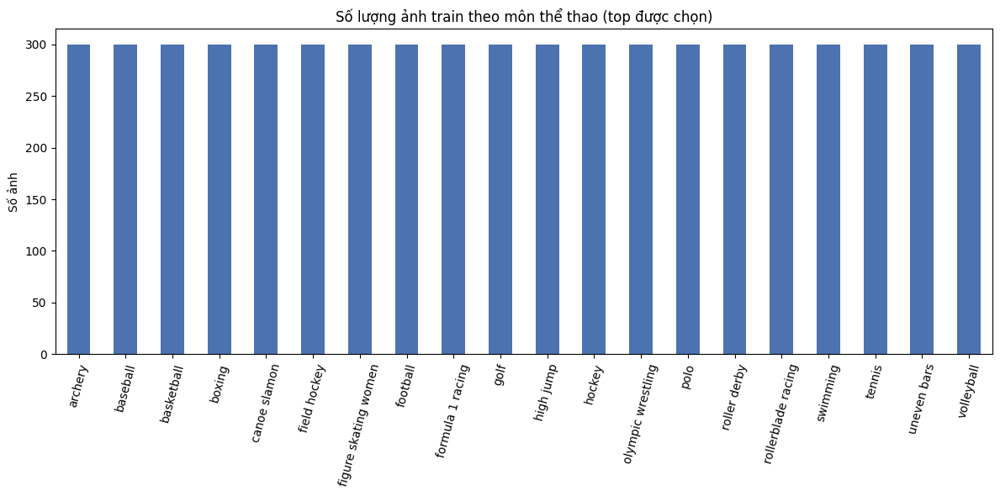

In [14]:
plt.figure(figsize=(12, 6))
train_counts.loc[SELECTED_CLASSES].plot(kind="bar", color="#4C72B0")
plt.title("Số lượng ảnh train theo môn thể thao (top được chọn)")
plt.ylabel("Số ảnh")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()


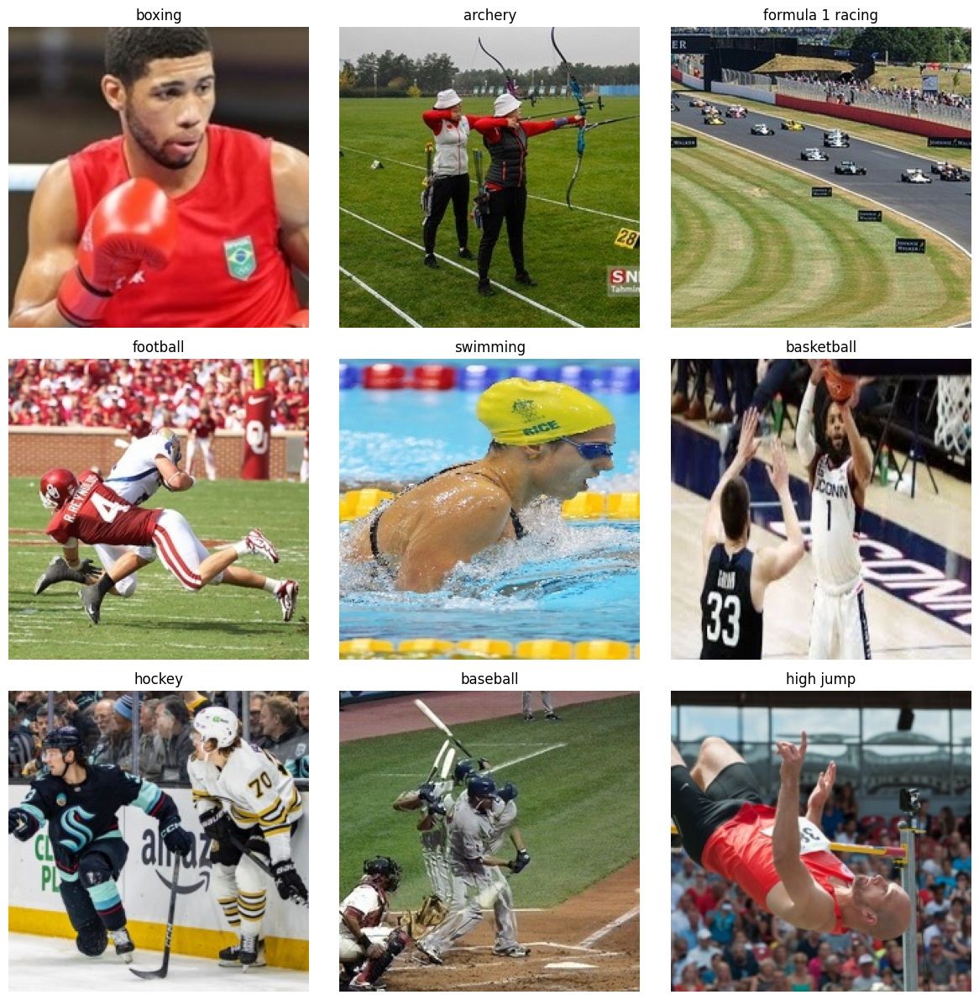

In [8]:
def show_sample_images(directory, classes, n_per_class=1, seed=SEED):
    rng = random.Random(seed)
    chosen = rng.sample(classes, min(9, len(classes)))
    plt.figure(figsize=(12, 12))
    for i, c in enumerate(chosen):
        files = glob.glob(os.path.join(directory, c, "*"))
        if not files:
            continue
        f = rng.choice(files)
        img = cv2.cvtColor(cv2.imread(f), cv2.COLOR_BGR2RGB)
        plt.subplot(3, 3, i + 1)
        plt.imshow(img)
        plt.title(c)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

show_sample_images(TRAIN_DIR, SELECTED_CLASSES)


## 4. Xây dựng pipeline dữ liệu (tiền xử lý + Data Augmentation)

Dùng `image_dataset_from_directory` để tạo `tf.data.Dataset`, chỉ giữ lại các lớp trong `SELECTED_CLASSES`.
Augmentation (lật ngang, xoay nhẹ, zoom, chỉnh sáng) được áp dụng **chỉ trên tập train** để giảm overfitting.


In [12]:
def make_filtered_dataset(directory, classes, img_size=IMG_SIZE, batch_size=BATCH_SIZE, shuffle=True):
    ds = tf.keras.utils.image_dataset_from_directory(
        directory,
        labels="inferred",
        label_mode="int",
        class_names=sorted(classes),
        image_size=img_size,
        batch_size=batch_size,
        shuffle=shuffle,
        seed=SEED,
    )
    return ds

train_ds_raw = make_filtered_dataset(TRAIN_DIR, SELECTED_CLASSES, shuffle=True)
valid_ds_raw = make_filtered_dataset(VALID_DIR, SELECTED_CLASSES, shuffle=False)
test_ds_raw  = make_filtered_dataset(TEST_DIR, SELECTED_CLASSES, shuffle=False)

CLASS_NAMES = train_ds_raw.class_names
NUM_CLASSES = len(CLASS_NAMES)
print("Số lớp:", NUM_CLASSES)
print(CLASS_NAMES)


Found 6000 files belonging to 20 classes.
Found 100 files belonging to 20 classes.
Found 100 files belonging to 20 classes.
Số lớp: 20
['archery', 'baseball', 'basketball', 'boxing', 'canoe slamon', 'field hockey', 'figure skating women', 'football', 'formula 1 racing', 'golf', 'high jump', 'hockey', 'olympic wrestling', 'polo', 'roller derby', 'rollerblade racing', 'swimming', 'tennis', 'uneven bars', 'volleyball']


In [13]:
# ==== NÂNG CẤP V3: BỘ TĂNG CƯỜNG DỮ LIỆU ĐẶC TRỊ CAMERA (CAMERA-RESILIENT) ====
# Chống lóa sáng màn hình điện thoại, chịu nghiêng góc, thu phóng và thích ứng ánh sáng thực tế
data_augmentation = keras.Sequential([
    # 1. Biến đổi hình học & góc nhìn (Geometric)
    layers.RandomFlip("horizontal"),                       # Lật ngang (trái/phải)
    layers.RandomRotation(0.15),                           # Xoay nghiêng góc ±15% (~54 độ)
    layers.RandomZoom(height_factor=(-0.2, 0.2)),          # Thu phóng xa/gần (chụp toàn cảnh hoặc cận cảnh)
    layers.RandomTranslation(0.10, 0.10),                  # Dịch chuyển vị trí chủ thể lệch tâm

    # 2. Xử lý quang học & cảm biến camera (Photometric & Sensor)
    layers.RandomContrast(0.30),                           # Chống lóa sáng màn hình và đèn flash
    layers.RandomBrightness(0.30, value_range=(0, 255)),   # Thích nghi phòng tối, ngoài trời nắng
    layers.GaussianNoise(0.05),                            # Giả lập nhiễu hạt sensor webcam/điện thoại
], name="data_augmentation")

AUTOTUNE = tf.data.AUTOTUNE
SHUFFLE_BUFFER = 1000

def prep_dataset(ds, augment=False, preprocess_fn=None, cache=True, onehot=False):
    """onehot=True: đổi nhãn int -> one-hot (cần cho CategoricalCrossentropy có label smoothing).
    Chỉ dùng onehot cho tập train/valid khi fit; tập test giữ nhãn int để dùng với sklearn."""
    if cache:
        ds = ds.cache()
    if augment:
        ds = ds.unbatch().shuffle(SHUFFLE_BUFFER, seed=SEED, reshuffle_each_iteration=True).batch(BATCH_SIZE)
        ds = ds.map(lambda x, y: (data_augmentation(x, training=True), y), num_parallel_calls=AUTOTUNE)
    if preprocess_fn is not None:
        ds = ds.map(lambda x, y: (preprocess_fn(x), y), num_parallel_calls=AUTOTUNE)
    if onehot:
        ds = ds.map(lambda x, y: (x, tf.one_hot(y, NUM_CLASSES)), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)


### 4.1. Trực quan hóa dữ liệu sau khi Tăng cường (Visualizing Augmentation Grid 3×3)
Mỗi lần chạy sẽ áp dụng ngẫu nhiên các phép lật, xoay nghiêng, co giãn, chỉnh tương phản/độ sáng và nhiễu hạt lên ảnh gốc.

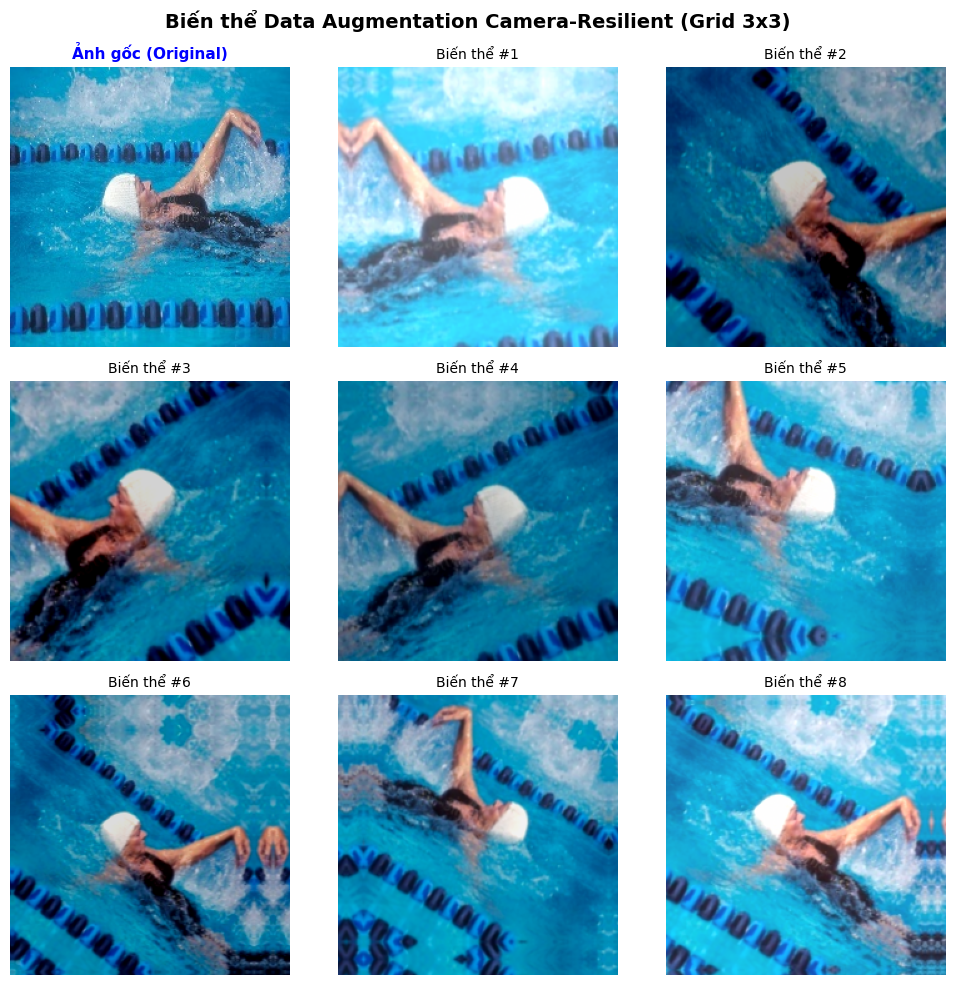

In [14]:
# ==== TRỰC QUAN HÓA DATA AUGMENTATION (GRID 3x3) ====
# Lấy 1 bức ảnh mẫu từ tập train và hiển thị 9 biến thể ngẫu nhiên mà mô hình sẽ học
def visualize_augmentation(dataset_raw, augment_layer, title="Biến thể Data Augmentation Camera-Resilient (Grid 3x3)"):
    for images, _ in dataset_raw.take(1):
        sample_img = images[0]
        break

    plt.figure(figsize=(10, 10))
    # Hiển thị ảnh gốc ở ô đầu tiên
    plt.subplot(3, 3, 1)
    plt.imshow(sample_img.numpy().astype("uint8"))
    plt.title("Ảnh gốc (Original)", fontsize=11, fontweight="bold", color="blue")
    plt.axis("off")

    # 8 ô còn lại hiển thị các biến thể sau augmentation
    for i in range(1, 9):
        augmented_img = augment_layer(tf.expand_dims(sample_img, 0), training=True)
        clipped_img = tf.clip_by_value(augmented_img[0], 0, 255).numpy().astype("uint8")
        plt.subplot(3, 3, i + 1)
        plt.imshow(clipped_img)
        plt.title(f"Biến thể #{i}", fontsize=10)
        plt.axis("off")

    plt.suptitle(title, fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()

# Hiển thị trực quan ngay lập tức
visualize_augmentation(train_ds_raw, data_augmentation)


## 5. Xây dựng các mô hình

Ba mô hình sẽ được huấn luyện và so sánh:
1. **CNN từ đầu** (baseline, không dùng pretrained weights)
2. **MobileNetV2** (transfer learning, fine-tune)
3. **ResNet50** (transfer learning, fine-tune) — đại diện họ ResNet (thay cho ResNet18)


In [15]:
def conv_bn(x, filters, name=None):
    x = layers.Conv2D(filters, 3, activation="relu", padding="same", name=name)(x)
    return layers.BatchNormalization()(x)   # BN đặt SAU ReLU -> lớp Conv "last_conv" vẫn là mục tiêu Grad-CAM hợp lệ

def build_cnn_scratch(input_shape, num_classes):
    inputs = keras.Input(shape=input_shape)
    x = layers.Rescaling(1.0 / 255)(inputs)
    x = conv_bn(x, 32);  x = layers.MaxPooling2D()(x)
    x = conv_bn(x, 64);  x = conv_bn(x, 64);   x = layers.MaxPooling2D()(x)
    x = conv_bn(x, 128); x = conv_bn(x, 128);  x = layers.MaxPooling2D()(x)
    x = conv_bn(x, 256, name="last_conv");     x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="CNN_Scratch")


def build_transfer_model(base_class, input_shape, num_classes, name):
    base = base_class(include_top=False, weights="imagenet", input_shape=input_shape)
    base.trainable = False  # đóng băng ban đầu, sẽ fine-tune sau
    inputs = keras.Input(shape=input_shape)
    x = base(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    model = keras.Model(inputs, outputs, name=name)
    return model, base


INPUT_SHAPE = IMG_SIZE + (3,)

cnn_scratch = build_cnn_scratch(INPUT_SHAPE, NUM_CLASSES)
cnn_scratch.summary()


Model: "CNN_Scratch"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 56, 56, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ last_conv (Conv2D)              │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 646,548 (2.47 MB)

 Trainable params: 645,204 (2.46 MB)

 Non-trainable params: 1,344 (5.25 KB)

## 6. Huấn luyện & so sánh 3 mô hình

In [18]:
EPOCHS_HEAD = 10       # huấn luyện đầu (frozen base với 2 mô hình transfer)
EPOCHS_FINETUNE = 25   # fine-tune thêm (EarlyStopping sẽ dừng đúng lúc)
FINETUNE_LR = 3e-5     # đỉnh của cosine decay khi fine-tune
UNFREEZE = {"MobileNetV2": 80, "ResNet50": 120}   # số lớp cuối của base được mở khóa

def make_loss():
    return keras.losses.CategoricalCrossentropy(label_smoothing=LABEL_SMOOTHING)

def cosine_schedule(peak_lr, total_epochs, min_lr=1e-7, warmup_epochs=1):
    def fn(epoch):
        if epoch < warmup_epochs:
            return peak_lr * (epoch + 1) / (warmup_epochs + 1)
        t = (epoch - warmup_epochs) / max(1, total_epochs - warmup_epochs)
        return min_lr + 0.5 * (peak_lr - min_lr) * (1 + math.cos(math.pi * min(1.0, t)))
    return fn

def get_callbacks(name, checkpoint=True, plateau=True, lr_fn=None, patience=8):
    cbs = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True)]
    if checkpoint:
        cbs.append(keras.callbacks.ModelCheckpoint(f"{name}_best.keras", monitor="val_loss", save_best_only=True))
    if plateau:
        cbs.append(keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2))
    if lr_fn is not None:
        cbs.append(keras.callbacks.LearningRateScheduler(lr_fn))
    return cbs

def freeze_batchnorm(base_model):
    """Đóng băng BatchNorm khi fine-tune để không phá thống kê ImageNet trên tập nhỏ."""
    for layer in base_model.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False

def unfreeze_top_layers(base_model, n_layers):
    """Progressive unfreezing: chỉ mở khóa n_layers cuối của base, BN vẫn đóng băng."""
    base_model.trainable = True
    for layer in base_model.layers[:-n_layers]:
        layer.trainable = False
    freeze_batchnorm(base_model)

def quick_acc(model, ds):
    """Accuracy trên ds có nhãn int (test), không phụ thuộc loss của model."""
    y = np.concatenate([b.numpy() for _, b in ds])
    return accuracy_score(y, np.argmax(model.predict(ds, verbose=0), axis=1))

def train_transfer_model(base_class, preprocess_fn, name, train_raw, valid_raw,
                         unfreeze_n, head_eval_ds=None, checkpoint=True,
                         epochs_head=None, epochs_ft=None, verbose=1):
    """Huấn luyện 2 giai đoạn: (1) head với base đóng băng, (2) fine-tune top layers + cosine LR.
    Trả về (model, base, history_gộp, info). info['head_test_acc'] = accuracy khi CHỈ train head (Frozen)."""
    epochs_head = EPOCHS_HEAD if epochs_head is None else epochs_head
    epochs_ft = EPOCHS_FINETUNE if epochs_ft is None else epochs_ft
    model, base = build_transfer_model(base_class, INPUT_SHAPE, NUM_CLASSES, f"{name}_Transfer")
    tr = prep_dataset(train_raw, augment=True,  preprocess_fn=preprocess_fn, onehot=True)
    va = prep_dataset(valid_raw, augment=False, preprocess_fn=preprocess_fn, onehot=True)

    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss=make_loss(), metrics=["accuracy"])
    h1 = model.fit(tr, validation_data=va, epochs=epochs_head, verbose=verbose,
                   callbacks=get_callbacks(f"{name}_head", checkpoint=checkpoint))
    info = {}
    if head_eval_ds is not None:
        info["head_test_acc"] = quick_acc(model, head_eval_ds)

    unfreeze_top_layers(base, unfreeze_n)
    model.compile(optimizer=keras.optimizers.Adam(FINETUNE_LR), loss=make_loss(), metrics=["accuracy"])
    h2 = model.fit(tr, validation_data=va, epochs=epochs_ft, verbose=verbose,
                   callbacks=get_callbacks(f"{name}_finetune", checkpoint=checkpoint, plateau=False,
                                           lr_fn=cosine_schedule(FINETUNE_LR, epochs_ft), patience=10))
    hist = {k: h1.history[k] + h2.history[k] for k in h1.history if k in h2.history}
    return model, base, hist, info

histories = {}
head_only_acc = {}   # accuracy test khi chỉ train head (Frozen) -> so sánh Frozen vs Fine-tuning

In [14]:
# ---- 1) CNN từ đầu ----
train_ds = prep_dataset(train_ds_raw, augment=True, onehot=True)
valid_ds = prep_dataset(valid_ds_raw, augment=False, onehot=True)
test_ds  = prep_dataset(test_ds_raw, augment=False)          # nhãn int

cnn_scratch.compile(optimizer=keras.optimizers.Adam(1e-3), loss=make_loss(), metrics=["accuracy"])

EPOCHS_SCRATCH = 50
hist_cnn = cnn_scratch.fit(
    train_ds, validation_data=valid_ds, epochs=EPOCHS_SCRATCH,
    callbacks=get_callbacks("cnn_scratch", plateau=False,
                            lr_fn=cosine_schedule(1e-3, EPOCHS_SCRATCH, min_lr=1e-6, warmup_epochs=2),
                            patience=12))
histories["CNN_Scratch"] = hist_cnn.history


Epoch 1/50


E0000 00:00:1794337971.919772     151 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794337974.212769     151 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


    187/Unknown 113s 431ms/step - accuracy: 0.2402 - loss: 2.6775

E0000 00:00:1794338065.418565     148 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794338065.946028     148 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


    188/Unknown 126s 495ms/step - accuracy: 0.2406 - loss: 2.6762

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


188/188 ━━━━━━━━━━━━━━━━━━━━ 130s 518ms/step - accuracy: 0.3197 - loss: 2.4455 - val_accuracy: 0.0500 - val_loss: 4.0973 - learning_rate: 3.3333e-04
Epoch 2/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 44s 229ms/step - accuracy: 0.4163 - loss: 2.1875 - val_accuracy: 0.1300 - val_loss: 4.2142 - learning_rate: 6.6667e-04
Epoch 3/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 44s 228ms/step - accuracy: 0.4672 - loss: 2.0467 - val_accuracy: 0.3500 - val_loss: 2.7554 - learning_rate: 0.0010
Epoch 4/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 44s 228ms/step - accuracy: 0.5387 - loss: 1.8733 - val_accuracy: 0.5400 - val_loss: 1.9485 - learning_rate: 9.9893e-04
Epoch 5/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 44s 229ms/step - accuracy: 0.5748 - loss: 1.7660 - val_accuracy: 0.3700 - val_loss: 2.4583 - learning_rate: 9.9573e-04
Epoch 6/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 44s 225ms/step - accuracy: 0.6100 - loss: 1.6710 - val_accuracy: 0.4800 - val_loss: 2.1015 - learning_rate: 9.9040e-04
Epoch 7/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 44s 228ms/step - acc

In [15]:
# ---- 2) MobileNetV2 (transfer learning) ----
test_ds_mnv2  = prep_dataset(test_ds_raw, augment=False, preprocess_fn=mnv2_preprocess)
valid_ds_mnv2 = prep_dataset(valid_ds_raw, augment=False, preprocess_fn=mnv2_preprocess, onehot=True)

mobilenet_model, mobilenet_base, hist_mnv2, info_mnv2 = train_transfer_model(
    MobileNetV2, mnv2_preprocess, "MobileNetV2", train_ds_raw, valid_ds_raw,
    unfreeze_n=UNFREEZE["MobileNetV2"], head_eval_ds=test_ds_mnv2)
histories["MobileNetV2"] = hist_mnv2
head_only_acc["MobileNetV2"] = info_mnv2["head_test_acc"]


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 68s 281ms/step - accuracy: 0.5342 - loss: 1.9061 - val_accuracy: 0.8900 - val_loss: 1.1455 - learning_rate: 0.0010
Epoch 2/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 41s 213ms/step - accuracy: 0.7512 - loss: 1.3227 - val_accuracy: 0.9300 - val_loss: 0.9890 - learning_rate: 0.0010
Epoch 3/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 42s 218ms/step - accuracy: 0.8015 - loss: 1.2060 - val_accuracy: 0.9400 - val_loss: 0.9672 - learning_rate: 0.0010
Epoch 4/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 42s 218ms/step - accuracy: 0.8178 - loss: 1.1813 - val_accuracy: 0.9100 - val_loss: 0.9480 - learning_rate: 0.0010
Epoch 5/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 42s 218ms/step - accuracy: 0.8322 - loss: 1.1412 - val_accuracy: 0.9300 - val_loss: 0.9127 - learning_rate: 0.0010
Epoch 6/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 82s 218ms/step - accuracy: 0.8342 - loss: 1.1378 - val_accuracy: 0.9500 - val_loss: 0.9016 - learning_rate: 0.0010
Epoch 7/10
188/188 ━━

E0000 00:00:1794340596.665491     151 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


    188/Unknown 64s 247ms/step - accuracy: 0.8625 - loss: 1.0545

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


188/188 ━━━━━━━━━━━━━━━━━━━━ 71s 283ms/step - accuracy: 0.8675 - loss: 1.0394 - val_accuracy: 0.9300 - val_loss: 0.8906 - learning_rate: 1.5000e-05
Epoch 2/25
188/188 ━━━━━━━━━━━━━━━━━━━━ 59s 218ms/step - accuracy: 0.8872 - loss: 1.0022 - val_accuracy: 0.9500 - val_loss: 0.8385 - learning_rate: 3.0000e-05
Epoch 3/25
188/188 ━━━━━━━━━━━━━━━━━━━━ 42s 217ms/step - accuracy: 0.9075 - loss: 0.9531 - val_accuracy: 0.9500 - val_loss: 0.8222 - learning_rate: 2.9872e-05
Epoch 4/25
188/188 ━━━━━━━━━━━━━━━━━━━━ 42s 218ms/step - accuracy: 0.9182 - loss: 0.9249 - val_accuracy: 0.9400 - val_loss: 0.8112 - learning_rate: 2.9491e-05
Epoch 5/25
188/188 ━━━━━━━━━━━━━━━━━━━━ 42s 217ms/step - accuracy: 0.9322 - loss: 0.8877 - val_accuracy: 0.9700 - val_loss: 0.8183 - learning_rate: 2.8862e-05
Epoch 6/25
188/188 ━━━━━━━━━━━━━━━━━━━━ 42s 215ms/step - accuracy: 0.9412 - loss: 0.8650 - val_accuracy: 0.9600 - val_loss: 0.8019 - learning_rate: 2.7997e-05
Epoch 7/25
188/188 ━━━━━━━━━━━━━━━━━━━━ 42s 216ms/step - 

In [16]:
# ---- 3) ResNet50 (transfer learning) ----
test_ds_res  = prep_dataset(test_ds_raw, augment=False, preprocess_fn=resnet_preprocess)
valid_ds_res = prep_dataset(valid_ds_raw, augment=False, preprocess_fn=resnet_preprocess, onehot=True)

resnet_model, resnet_base, hist_res, info_res = train_transfer_model(
    ResNet50, resnet_preprocess, "ResNet50", train_ds_raw, valid_ds_raw,
    unfreeze_n=UNFREEZE["ResNet50"], head_eval_ds=test_ds_res)
histories["ResNet50"] = hist_res
head_only_acc["ResNet50"] = info_res["head_test_acc"]


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
Epoch 1/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 79s 338ms/step - accuracy: 0.6053 - loss: 1.7607 - val_accuracy: 0.9400 - val_loss: 0.9326 - learning_rate: 0.0010
Epoch 2/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 47s 244ms/step - accuracy: 0.8097 - loss: 1.2150 - val_accuracy: 0.9600 - val_loss: 0.9065 - learning_rate: 0.0010
Epoch 3/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 48s 247ms/step - accuracy: 0.8505 - loss: 1.1272 - val_accuracy: 0.9800 - val_loss: 0.8687 - learning_rate: 0.0010
Epoch 4/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 81s 244ms/step - accuracy: 0.8598 - loss: 1.0900 - val_accuracy: 0.9700 - val_loss: 0.8618 - learning_rate: 0.0010
Epoch 5/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 46s 240ms/step - accuracy: 0.8758 - loss: 1.0612 - val_accuracy: 0.9600 - val_loss: 0.8732 - learning_rate: 0.0010
Epoch 6/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 82s 239ms/step - accuracy: 0.8855 - loss: 1.0331 - val_accuracy: 0.9700 - val_loss: 0.8748 - learning_rate: 0.0010
Epoch 7/10
188/188 

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


188/188 ━━━━━━━━━━━━━━━━━━━━ 96s 354ms/step - accuracy: 0.9250 - loss: 0.9195 - val_accuracy: 1.0000 - val_loss: 0.7793 - learning_rate: 1.5000e-05
Epoch 2/25
188/188 ━━━━━━━━━━━━━━━━━━━━ 50s 257ms/step - accuracy: 0.9372 - loss: 0.8884 - val_accuracy: 0.9500 - val_loss: 0.8447 - learning_rate: 3.0000e-05
Epoch 3/25
188/188 ━━━━━━━━━━━━━━━━━━━━ 51s 264ms/step - accuracy: 0.9598 - loss: 0.8276 - val_accuracy: 0.9900 - val_loss: 0.7619 - learning_rate: 2.9872e-05
Epoch 4/25
188/188 ━━━━━━━━━━━━━━━━━━━━ 50s 258ms/step - accuracy: 0.9718 - loss: 0.7885 - val_accuracy: 0.9700 - val_loss: 0.7810 - learning_rate: 2.9491e-05
Epoch 5/25
188/188 ━━━━━━━━━━━━━━━━━━━━ 49s 251ms/step - accuracy: 0.9768 - loss: 0.7655 - val_accuracy: 0.9600 - val_loss: 0.7824 - learning_rate: 2.8862e-05
Epoch 6/25
188/188 ━━━━━━━━━━━━━━━━━━━━ 51s 263ms/step - accuracy: 0.9837 - loss: 0.7470 - val_accuracy: 0.9700 - val_loss: 0.7652 - learning_rate: 2.7997e-05
Epoch 7/25
188/188 ━━━━━━━━━━━━━━━━━━━━ 55s 285ms/step - 

/tmp/ipykernel_7269/622736152.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Accuracy"); axes[0].legend()
/tmp/ipykernel_7269/622736152.py:9: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Loss"); axes[1].legend()


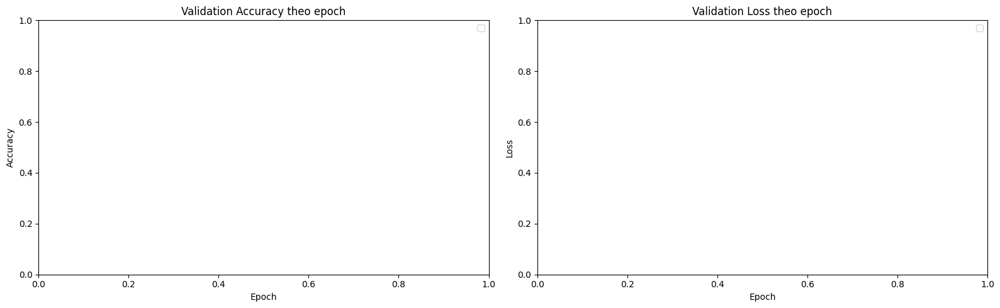

In [30]:
# Biểu đồ so sánh accuracy / loss giữa 3 mô hình
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for name, h in histories.items():
    axes[0].plot(h["val_accuracy"], label=name)
    axes[1].plot(h["val_loss"], label=name)
axes[0].set_title("Validation Accuracy theo epoch")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Accuracy"); axes[0].legend()
axes[1].set_title("Validation Loss theo epoch")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Loss"); axes[1].legend()
plt.tight_layout()
plt.show()


## 7. Đánh giá trên tập test: Accuracy, Classification Report, Confusion Matrix

In [25]:
WORK = "/kaggle/working"   # hoặc đường dẫn Dataset bạn vừa tạo

cnn_scratch     = keras.models.load_model(f"{WORK}/cnn_scratch_best.keras", compile=False)
mobilenet_model = keras.models.load_model(f"{WORK}/MobileNetV2_finetune_best.keras", compile=False)
resnet_model    = keras.models.load_model(f"{WORK}/ResNet50_finetune_best.keras", compile=False)

test_ds       = prep_dataset(test_ds_raw, augment=False)
test_ds_mnv2  = prep_dataset(test_ds_raw, augment=False, preprocess_fn=mnv2_preprocess)
test_ds_res   = prep_dataset(test_ds_raw, augment=False, preprocess_fn=resnet_preprocess)
valid_ds      = prep_dataset(valid_ds_raw, augment=False, onehot=True)
valid_ds_mnv2 = prep_dataset(valid_ds_raw, augment=False, preprocess_fn=mnv2_preprocess, onehot=True)
valid_ds_res  = prep_dataset(valid_ds_raw, augment=False, preprocess_fn=resnet_preprocess, onehot=True)

# Accuracy "Frozen" lấy từ checkpoint giai đoạn head
histories, head_only_acc = {}, {}
for name, ds in [("MobileNetV2", test_ds_mnv2), ("ResNet50", test_ds_res)]:
    m = keras.models.load_model(f"{WORK}/{name}_head_best.keras", compile=False)
    head_only_acc[name] = quick_acc(m, ds)
print(head_only_acc)

{'MobileNetV2': 0.95, 'ResNet50': 0.94}


===== CNN_Scratch — Test Accuracy: 0.8000 =====
                      precision    recall  f1-score   support

             archery       0.50      0.60      0.55         5
            baseball       0.67      0.80      0.73         5
          basketball       0.45      1.00      0.62         5
              boxing       1.00      1.00      1.00         5
        canoe slamon       1.00      1.00      1.00         5
        field hockey       1.00      0.80      0.89         5
figure skating women       1.00      1.00      1.00         5
            football       0.75      0.60      0.67         5
    formula 1 racing       0.83      1.00      0.91         5
                golf       0.57      0.80      0.67         5
           high jump       0.83      1.00      0.91         5
              hockey       1.00      0.80      0.89         5
   olympic wrestling       0.80      0.80      0.80         5
                polo       1.00      1.00      1.00         5
        roller derby 

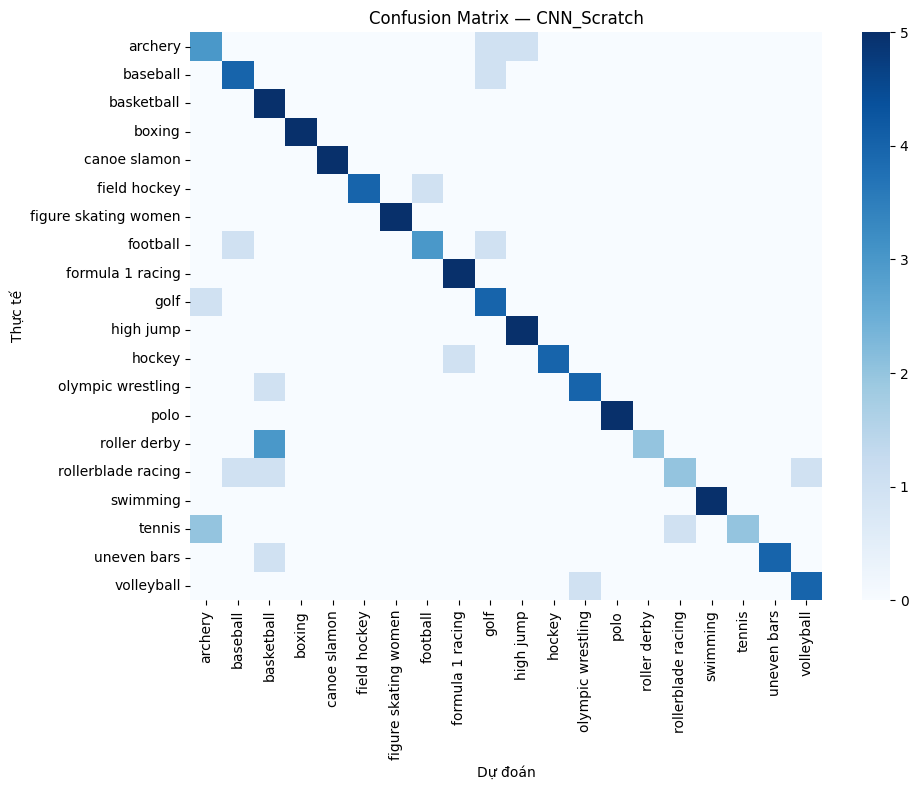

===== MobileNetV2 — Test Accuracy: 0.9700 =====
                      precision    recall  f1-score   support

             archery       1.00      1.00      1.00         5
            baseball       1.00      0.80      0.89         5
          basketball       0.83      1.00      0.91         5
              boxing       0.80      0.80      0.80         5
        canoe slamon       1.00      1.00      1.00         5
        field hockey       1.00      1.00      1.00         5
figure skating women       1.00      1.00      1.00         5
            football       1.00      1.00      1.00         5
    formula 1 racing       1.00      1.00      1.00         5
                golf       1.00      1.00      1.00         5
           high jump       1.00      1.00      1.00         5
              hockey       1.00      1.00      1.00         5
   olympic wrestling       1.00      1.00      1.00         5
                polo       1.00      1.00      1.00         5
        roller derby 

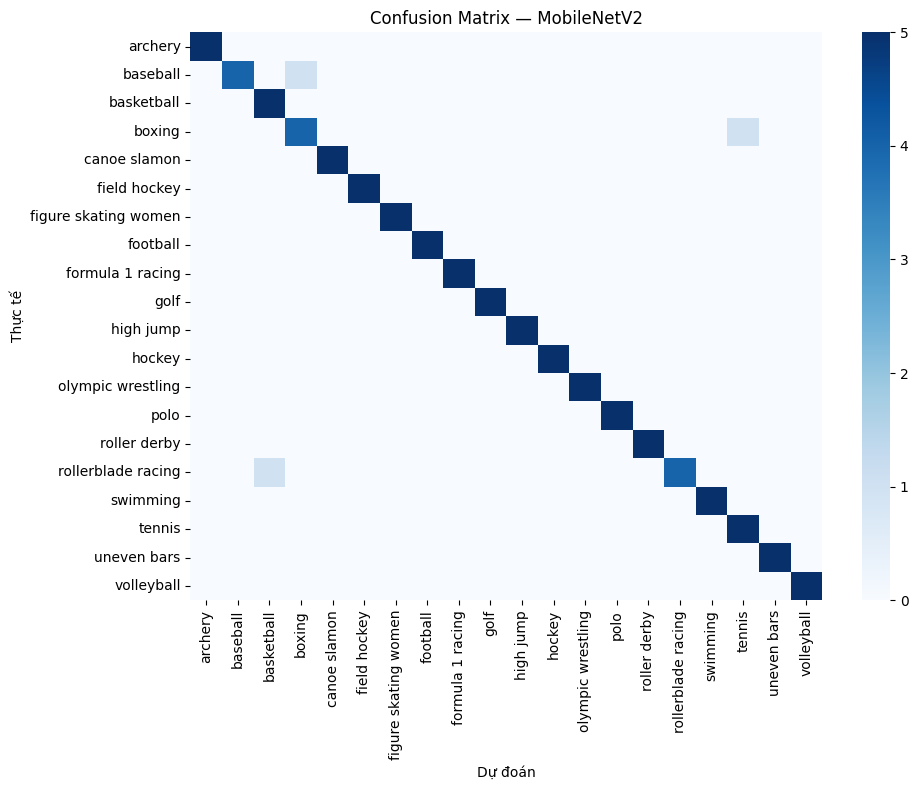

===== ResNet50 — Test Accuracy: 1.0000 =====
                      precision    recall  f1-score   support

             archery       1.00      1.00      1.00         5
            baseball       1.00      1.00      1.00         5
          basketball       1.00      1.00      1.00         5
              boxing       1.00      1.00      1.00         5
        canoe slamon       1.00      1.00      1.00         5
        field hockey       1.00      1.00      1.00         5
figure skating women       1.00      1.00      1.00         5
            football       1.00      1.00      1.00         5
    formula 1 racing       1.00      1.00      1.00         5
                golf       1.00      1.00      1.00         5
           high jump       1.00      1.00      1.00         5
              hockey       1.00      1.00      1.00         5
   olympic wrestling       1.00      1.00      1.00         5
                polo       1.00      1.00      1.00         5
        roller derby    

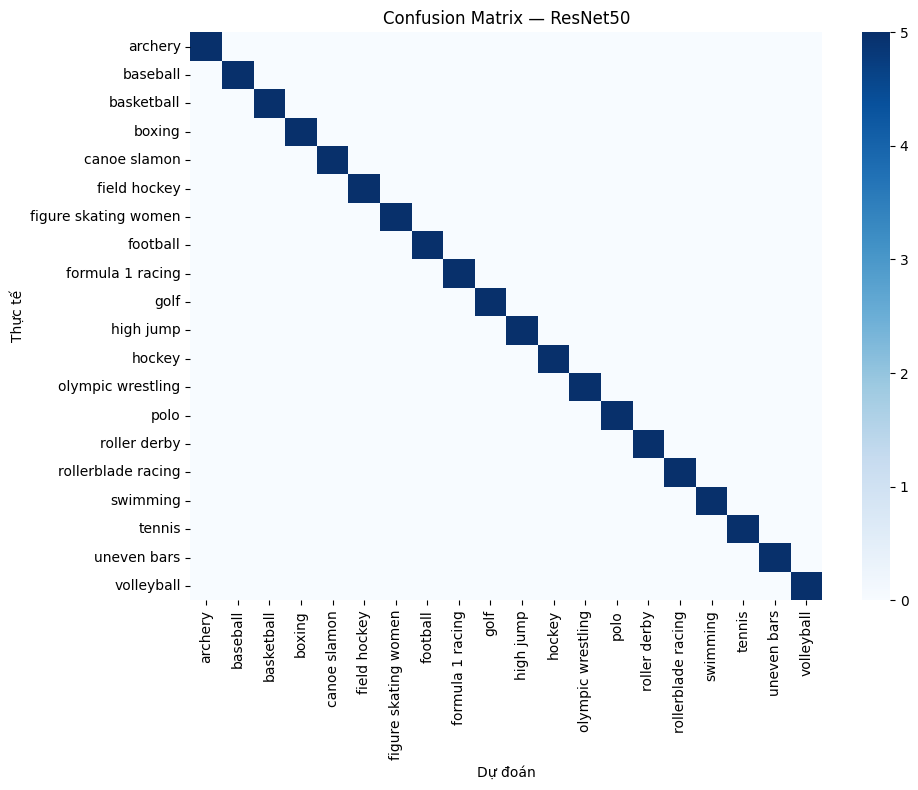

In [26]:
eval_store = {}   # lưu (y_true, xác suất dự đoán) để dùng lại cho phân tích lỗi / ensemble, không phải predict lại

def evaluate_model(model, ds, class_names, name):
    # ds test KHÔNG shuffle nên thứ tự nhãn và thứ tự dự đoán luôn khớp nhau.
    # Predict cả dataset 1 lần (nhanh hơn và không bị cảnh báo tf.function retracing như predict từng batch).
    y_true = np.concatenate([y.numpy() for _, y in ds])
    probs = model.predict(ds, verbose=0)
    y_pred = np.argmax(probs, axis=1)
    eval_store[name] = (y_true, probs)

    acc = accuracy_score(y_true, y_pred)
    print(f"===== {name} — Test Accuracy: {acc:.4f} =====")
    print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=False, cmap="Blues", xticklabels=class_names, yticklabels=class_names)
    plt.title(f"Confusion Matrix — {name}")
    plt.xlabel("Dự đoán"); plt.ylabel("Thực tế")
    plt.xticks(rotation=90); plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()
    return acc

results = {}
results["CNN_Scratch"] = evaluate_model(cnn_scratch, test_ds, CLASS_NAMES, "CNN_Scratch")
results["MobileNetV2"] = evaluate_model(mobilenet_model, test_ds_mnv2, CLASS_NAMES, "MobileNetV2")
results["ResNet50"] = evaluate_model(resnet_model, test_ds_res, CLASS_NAMES, "ResNet50")


In [27]:
summary_df = pd.DataFrame({
    "Mô hình": list(results.keys()),
    "Test Accuracy": [round(v, 4) for v in results.values()],
}).sort_values("Test Accuracy", ascending=False).reset_index(drop=True)

summary_df["Đạt mục tiêu (>=0.88)"] = summary_df["Test Accuracy"] >= 0.88
print(summary_df.to_string(index=False))

# So sánh Frozen (chỉ train head) vs Fine-tuning – theo bản phân công của nhóm
ft_df = pd.DataFrame({
    "Mô hình": list(head_only_acc.keys()),
    "Test Acc (Frozen)": [round(v, 4) for v in head_only_acc.values()],
    "Test Acc (Fine-tune)": [round(results[k], 4) for k in head_only_acc],
})
ft_df["Chênh lệch"] = (ft_df["Test Acc (Fine-tune)"] - ft_df["Test Acc (Frozen)"]).round(4)
print(ft_df.to_string(index=False))


    Mô hình  Test Accuracy  Đạt mục tiêu (>=0.88)
   ResNet50           1.00                   True
MobileNetV2           0.97                   True
CNN_Scratch           0.80                  False
    Mô hình  Test Acc (Frozen)  Test Acc (Fine-tune)  Chênh lệch
MobileNetV2               0.95                  0.97        0.02
   ResNet50               0.94                  1.00        0.06


### 7b. Phân tích lỗi (các cặp lớp bị nhầm) & thử Ensemble

Tập test chỉ có **5 ảnh/lớp (100 ảnh)** nên 1 ảnh sai ≈ 1% accuracy; chênh lệch 1–2% giữa các mô hình chưa đủ để kết luận mô hình nào "thật sự" tốt hơn.


In [28]:
def top_confusions(name, class_names, k=8):
    y_true, probs = eval_store[name]
    y_pred = probs.argmax(1)
    cm = confusion_matrix(y_true, y_pred, labels=list(range(len(class_names))))
    np.fill_diagonal(cm, 0)
    pairs = sorted([(cm[i, j], class_names[i], class_names[j])
                    for i in range(len(cm)) for j in range(len(cm)) if cm[i, j] > 0], reverse=True)
    print(f"--- {name}: các cặp bị nhầm nhiều nhất (Thực tế -> Dự đoán) ---")
    for n, t, p in pairs[:k]:
        print(f"  {t} -> {p}: {n} ảnh")
    print()

for n in ["CNN_Scratch", "MobileNetV2", "ResNet50"]:
    top_confusions(n, CLASS_NAMES)

# Ensemble: trung bình xác suất MobileNetV2 + ResNet50 (chỉ để thử nghiệm/báo cáo; không lưu thành 1 file model)
y_m, p_m = eval_store["MobileNetV2"]
y_r, p_r = eval_store["ResNet50"]
assert (y_m == y_r).all(), "Thứ tự test của 2 mô hình không khớp"
ens_acc = accuracy_score(y_m, (p_m + p_r).argmax(1))
print(f"Ensemble MobileNetV2 + ResNet50 — Test Accuracy: {ens_acc:.4f}")
print(f"(Test có {len(y_m)} ảnh: 1 ảnh sai = {100 / len(y_m):.0f}% accuracy)")

# ---- TTA (lật ngang) + ensemble có trọng số ----
def predict_probs_tta(model, ds):
    flipped = ds.map(lambda x, y: (tf.image.flip_left_right(x), y))
    return (model.predict(ds, verbose=0) + model.predict(flipped, verbose=0)) / 2

p_m_tta = predict_probs_tta(mobilenet_model, test_ds_mnv2)
p_r_tta = predict_probs_tta(resnet_model, test_ds_res)
print(f"MobileNetV2 + TTA         : {accuracy_score(y_m, p_m_tta.argmax(1)):.4f}")
print(f"ResNet50    + TTA         : {accuracy_score(y_m, p_r_tta.argmax(1)):.4f}")
print(f"Ensemble (0.3/0.7) + TTA  : {accuracy_score(y_m, (0.3 * p_m_tta + 0.7 * p_r_tta).argmax(1)):.4f}")
print("Lưu ý: chênh lệch 1 ảnh = 1% trên tập test 100 ảnh -> hãy dựa vào K-Fold (mục 7c) để kết luận.")


--- CNN_Scratch: các cặp bị nhầm nhiều nhất (Thực tế -> Dự đoán) ---
  roller derby -> basketball: 3 ảnh
  tennis -> archery: 2 ảnh
  volleyball -> olympic wrestling: 1 ảnh
  uneven bars -> basketball: 1 ảnh
  tennis -> rollerblade racing: 1 ảnh
  rollerblade racing -> volleyball: 1 ảnh
  rollerblade racing -> basketball: 1 ảnh
  rollerblade racing -> baseball: 1 ảnh

--- MobileNetV2: các cặp bị nhầm nhiều nhất (Thực tế -> Dự đoán) ---
  rollerblade racing -> basketball: 1 ảnh
  boxing -> tennis: 1 ảnh
  baseball -> boxing: 1 ảnh

--- ResNet50: các cặp bị nhầm nhiều nhất (Thực tế -> Dự đoán) ---

Ensemble MobileNetV2 + ResNet50 — Test Accuracy: 0.9900
(Test có 100 ảnh: 1 ảnh sai = 1% accuracy)
MobileNetV2 + TTA         : 0.9700
ResNet50    + TTA         : 0.9900
Ensemble (0.3/0.7) + TTA  : 0.9900
Lưu ý: chênh lệch 1 ảnh = 1% trên tập test 100 ảnh -> hãy dựa vào K-Fold (mục 7c) để kết luận.


### 7c. Stratified K-Fold Cross-Validation (đánh giá đáng tin hơn)

Tập test chỉ có **100 ảnh** nên accuracy dao động ±vài % theo may rủi. Ở đây gộp **train + valid + test (3.511 ảnh)**,
chia `KFOLD` fold phân tầng theo lớp; mỗi fold: huấn luyện trên phần còn lại (trong đó 10% làm validation nội bộ để early stopping,
**fold giữ lại không bao giờ dùng để chọn epoch**), rồi dự đoán fold đó. Gộp dự đoán ngoài-fold (OOF) cho toàn bộ ảnh.

Bật bằng `RUN_KFOLD = True` ở mục 2.

In [21]:
# Nén toàn bộ các file .keras vào một file models.zip
!zip -j models.zip /kaggle/working/*.keras

# Tạo liên kết tải file về trực tiếp
from IPython.display import FileLink
FileLink(r'models.zip')

  adding: cnn_scratch_best.keras (deflated 9%)
  adding: MobileNetV2_finetune_best.keras (deflated 10%)
  adding: MobileNetV2_head_best.keras (deflated 12%)
  adding: ResNet50_finetune_best.keras (deflated 8%)
  adding: ResNet50_head_best.keras (deflated 8%)


/kaggle/working/models.zip

In [32]:
import gc
from sklearn.model_selection import StratifiedKFold, train_test_split

def collect_all_paths():
    paths, labels = [], []
    for d in {TRAIN_DIR, VALID_DIR, TEST_DIR}:
        for ci, cname in enumerate(CLASS_NAMES):
            for f in glob.glob(os.path.join(d, cname, "*")):
                paths.append(f); labels.append(ci)
    return np.array(paths), np.array(labels)

def _load(path, label):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)
    return img, label

def paths_to_ds(paths, labels, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle:
        ds = ds.shuffle(len(paths), seed=SEED)
    return ds.map(_load, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE)

def run_kfold(model_name=KFOLD_MODEL, k=KFOLD, epochs_head=6, epochs_ft=15):
    base_cls, pre = {"ResNet50": (ResNet50, resnet_preprocess),
                     "MobileNetV2": (MobileNetV2, mnv2_preprocess)}[model_name]
    paths, labels = collect_all_paths()
    print(f"Tổng số ảnh dùng cho K-Fold: {len(paths)} | {model_name} | {k} fold")
    oof_pred = np.zeros(len(paths), dtype=int)
    oof_prob = np.zeros((len(paths), NUM_CLASSES), dtype="float32")
    fold_acc = []
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=SEED)
    for fold, (tr_idx, te_idx) in enumerate(skf.split(paths, labels), 1):
        tr_idx, va_idx = train_test_split(tr_idx, test_size=0.1, stratify=labels[tr_idx], random_state=SEED)
        tr_raw = paths_to_ds(paths[tr_idx], labels[tr_idx], shuffle=True)
        va_raw = paths_to_ds(paths[va_idx], labels[va_idx])
        te_ds  = prep_dataset(paths_to_ds(paths[te_idx], labels[te_idx]), preprocess_fn=pre, cache=False)
        model, _, _, _ = train_transfer_model(base_cls, pre, f"{model_name}_fold{fold}", tr_raw, va_raw,
                                              unfreeze_n=UNFREEZE[model_name], checkpoint=False,
                                              epochs_head=epochs_head, epochs_ft=epochs_ft, verbose=0)
        probs = model.predict(te_ds, verbose=0)
        oof_prob[te_idx] = probs
        oof_pred[te_idx] = probs.argmax(1)
        acc = accuracy_score(labels[te_idx], oof_pred[te_idx])
        fold_acc.append(acc)
        print(f"  Fold {fold}/{k}: accuracy = {acc:.4f}  ({len(te_idx)} ảnh)")
        del model, tr_raw, va_raw, te_ds
        keras.backend.clear_session(); gc.collect()
    print(f"\n{model_name} {k}-Fold: {np.mean(fold_acc):.4f} ± {np.std(fold_acc):.4f}  |  OOF accuracy (toàn bộ ảnh): "
          f"{accuracy_score(labels, oof_pred):.4f}")
    return paths, labels, oof_pred, oof_prob, fold_acc

if RUN_KFOLD:
    kf_paths, kf_labels, kf_pred, kf_prob, kf_fold_acc = run_kfold()
    print(classification_report(kf_labels, kf_pred, target_names=CLASS_NAMES, zero_division=0))
    cm = confusion_matrix(kf_labels, kf_pred); np.fill_diagonal(cm, 0)
    pairs = sorted([(cm[i, j], CLASS_NAMES[i], CLASS_NAMES[j]) for i in range(NUM_CLASSES)
                    for j in range(NUM_CLASSES) if cm[i, j] > 0], reverse=True)[:10]
    print("Các cặp lớp bị nhầm nhiều nhất (OOF):")
    for n, t, p in pairs:
        print(f"  {t} -> {p}: {n} ảnh")
else:
    print("RUN_KFOLD = False -> bỏ qua K-Fold. Đặt RUN_KFOLD = True ở mục 2 để chạy.")


Tổng số ảnh dùng cho K-Fold: 6200 | ResNet50 | 5 fold


KeyboardInterrupt: 

## 8. Grad-CAM — Giải thích quyết định của mô hình

Grad-CAM giúp trả lời câu hỏi nghiên cứu chính: *đặc trưng thị giác nào (màu sân, trang phục, dụng cụ) đóng góp nhiều nhất vào quyết định phân loại?*
Ta trực quan hoá vùng ảnh mà mô hình "chú ý" nhiều nhất khi ra quyết định, cho cả CNN-scratch và MobileNetV2.


In [33]:
def get_last_conv_layer_name(model):
    """Lớp mục tiêu Grad-CAM.
    - Mạng nền lồng bên trong (MobileNetV2 / ResNet50): lớp CUỐI của base = đầu ra ngay trước GAP
      ('out_relu' của MobileNetV2, 'conv5_block3_out' của ResNet50).
    - CNN từ đầu: lớp 'last_conv'."""
    for layer in reversed(model.layers):
        if hasattr(layer, "layers"):
            return layer.layers[-1].name
    return "last_conv"


def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    # Tìm layer conv cuối: có thể nằm trực tiếp trong `model` (CNN từ đầu),
    # hoặc lồng bên trong một submodel pretrained (base MobileNetV2/ResNet50).
    target_layer = None
    base_submodel = None
    for layer in model.layers:
        if layer.name == last_conv_layer_name:
            target_layer = layer
            break
    if target_layer is None:
        for layer in model.layers:
            if hasattr(layer, "get_layer"):
                try:
                    target_layer = layer.get_layer(last_conv_layer_name)
                    base_submodel = layer
                    break
                except ValueError:
                    continue
    if target_layer is None:
        raise ValueError(f"Không tìm thấy layer '{last_conv_layer_name}' trong model.")

    if base_submodel is None:
        # Trường hợp CNN từ đầu: conv layer nằm ngay trong graph của `model`,
        # nên có thể dựng grad_model 1 giai đoạn như bình thường.
        grad_model = keras.Model(inputs=model.inputs, outputs=[target_layer.output, model.output])
        with tf.GradientTape() as tape:
            conv_outputs, predictions = grad_model(img_array)
            if pred_index is None:
                pred_index = tf.argmax(predictions[0])
            class_channel = predictions[:, pred_index]
        grads = tape.gradient(class_channel, conv_outputs)
    else:
        # Trường hợp transfer learning: conv layer nằm trong submodel pretrained (base),
        # được gọi như 1 layer duy nhất trong `model` -> không thể dựng 1 grad_model
        # bắc cầu qua 2 graph khác nhau. Tách thành 2 giai đoạn:
        #   (1) conv_model: input của base -> output của conv layer cuối
        #   (2) classifier_model: các layer sau base (GAP, Dropout, Dense...) áp lên conv_outputs
        conv_model = keras.Model(base_submodel.input, target_layer.output)

        classifier_layers = [l for l in model.layers if l is not model.layers[0] and l is not base_submodel]
        classifier_input = keras.Input(shape=conv_model.output.shape[1:])
        y = classifier_input
        for layer in classifier_layers:
            y = layer(y)
        classifier_model = keras.Model(classifier_input, y)

        with tf.GradientTape() as tape:
            conv_outputs = conv_model(img_array)
            tape.watch(conv_outputs)
            predictions = classifier_model(conv_outputs)
            if pred_index is None:
                pred_index = tf.argmax(predictions[0])
            class_channel = predictions[:, pred_index]
        grads = tape.gradient(class_channel, conv_outputs)

    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy(), int(pred_index)


def overlay_gradcam(img_rgb, heatmap, alpha=0.4):
    heatmap = cv2.resize(heatmap, (img_rgb.shape[1], img_rgb.shape[0]))
    heatmap = np.uint8(255 * heatmap)
    heatmap_color = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)
    heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)
    overlay = np.uint8(img_rgb * (1 - alpha) + heatmap_color * alpha)
    return overlay


Grad-CAM — MobileNetV2:


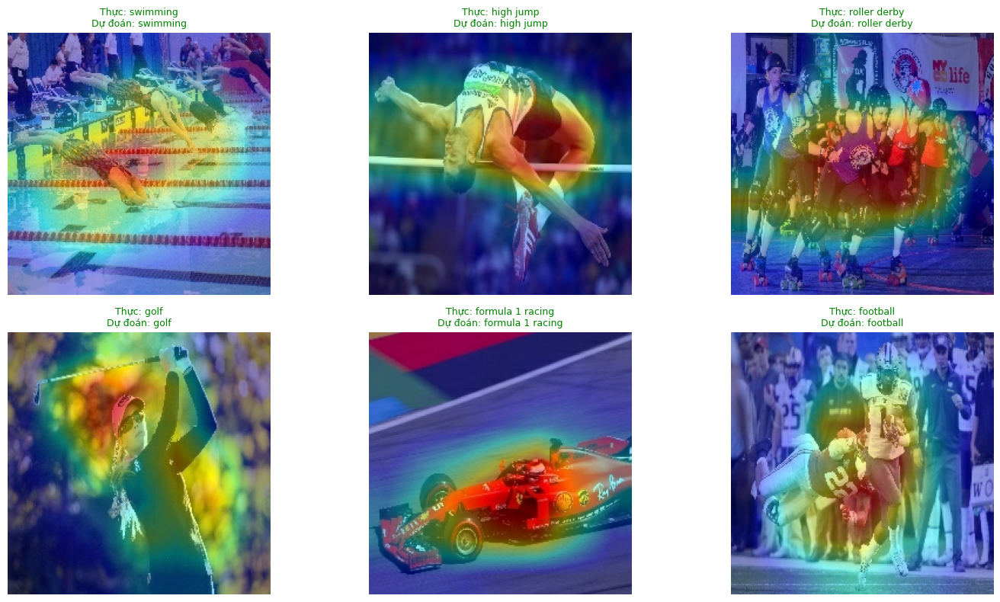

In [34]:
def show_gradcam_examples(model, ds_raw, preprocess_fn, class_names, n=6, seed=SEED):
    """Chọn ngẫu nhiên n ảnh test (test_ds_raw không shuffle nên take() chỉ ra vài ảnh đầu cùng 1 lớp)."""
    last_conv_name = get_last_conv_layer_name(model)
    all_imgs = np.concatenate([images.numpy() for images, _ in ds_raw])
    all_labels = np.concatenate([labels.numpy() for _, labels in ds_raw])
    chosen = np.random.RandomState(seed).choice(len(all_imgs), min(n, len(all_imgs)), replace=False)

    cols = max(1, math.ceil(len(chosen) / 2))
    rows = math.ceil(len(chosen) / cols)
    plt.figure(figsize=(5 * cols, 4 * rows))
    for k, idx in enumerate(chosen):
        img_rgb = all_imgs[idx].astype("uint8")
        x = tf.expand_dims(all_imgs[idx], 0)
        # CNN_Scratch đã có sẵn lớp Rescaling(1/255) bên trong -> KHÔNG chia 255 thêm lần nữa
        x = preprocess_fn(x) if preprocess_fn else x
        heatmap, pred_idx = make_gradcam_heatmap(x, model, last_conv_name)
        overlay = overlay_gradcam(img_rgb, heatmap)

        plt.subplot(rows, cols, k + 1)
        plt.imshow(overlay)
        true_label = class_names[all_labels[idx]]
        pred_label = class_names[pred_idx]
        color = "green" if true_label == pred_label else "red"
        plt.title(f"Thực: {true_label}\nDự đoán: {pred_label}", color=color, fontsize=9)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

print("Grad-CAM — MobileNetV2:")
show_gradcam_examples(mobilenet_model, test_ds_raw, mnv2_preprocess, CLASS_NAMES, n=6)

Nhãn Grad-CAM khớp dự đoán mô hình: 32/32 (phải bằng nhau)
Grad-CAM — MobileNetV2 (mỗi lớp 1 ảnh):


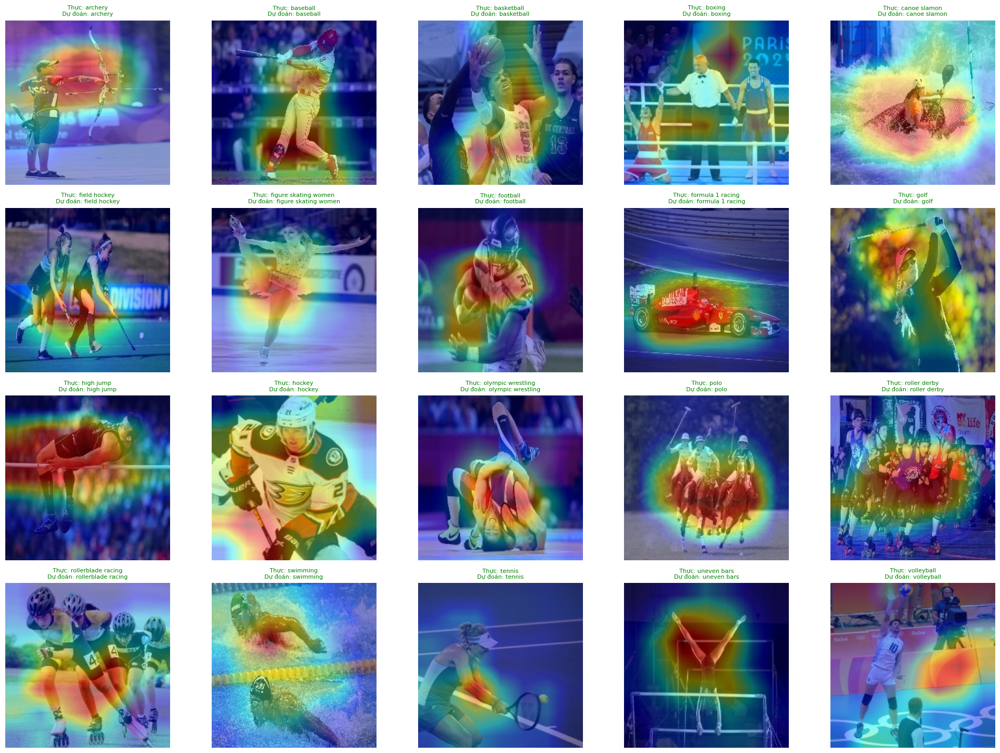

In [35]:
# Kiểm tra: nhãn dự đoán trong Grad-CAM phải KHỚP với dự đoán thật của mô hình
imgs, labs = next(iter(test_ds_raw))
n_check, n_match = 0, 0
for i in range(imgs.shape[0]):
    x = mnv2_preprocess(tf.expand_dims(imgs[i], 0))
    _, p_cam = make_gradcam_heatmap(x, mobilenet_model, get_last_conv_layer_name(mobilenet_model))
    p_true = int(np.argmax(mobilenet_model.predict(x, verbose=0)[0]))
    n_check += 1; n_match += int(p_cam == p_true)
print(f"Nhãn Grad-CAM khớp dự đoán mô hình: {n_match}/{n_check} (phải bằng nhau)")


def gradcam_one_per_class(model, ds_raw, preprocess_fn, class_names, cols=5):
    """Mỗi lớp lấy 1 ảnh (ảnh đầu tiên gặp trong tập test) để Grad-CAM đa dạng hơn."""
    name = get_last_conv_layer_name(model)
    seen, items = set(), []
    for images, labels in ds_raw:
        for i in range(images.shape[0]):
            y = int(labels[i])
            if y in seen:
                continue
            seen.add(y)
            items.append((images[i], y))
    items.sort(key=lambda t: t[1])
    rows = math.ceil(len(items) / cols)
    plt.figure(figsize=(4 * cols, 3.6 * rows))
    for k, (img, y) in enumerate(items):
        x = preprocess_fn(tf.expand_dims(img, 0)) if preprocess_fn else tf.expand_dims(img, 0)
        hm, p = make_gradcam_heatmap(x, model, name)
        ov = overlay_gradcam(img.numpy().astype("uint8"), hm)
        plt.subplot(rows, cols, k + 1)
        plt.imshow(ov)
        plt.axis("off")
        plt.title(f"Thực: {class_names[y]}\nDự đoán: {class_names[p]}",
                  color="green" if p == y else "red", fontsize=8)
    plt.tight_layout()
    plt.show()


print("Grad-CAM — MobileNetV2 (mỗi lớp 1 ảnh):")
gradcam_one_per_class(mobilenet_model, test_ds_raw, mnv2_preprocess, CLASS_NAMES)

Grad-CAM — các ảnh MobileNetV2 đoán sai:
Số ảnh test bị đoán sai: 3/100


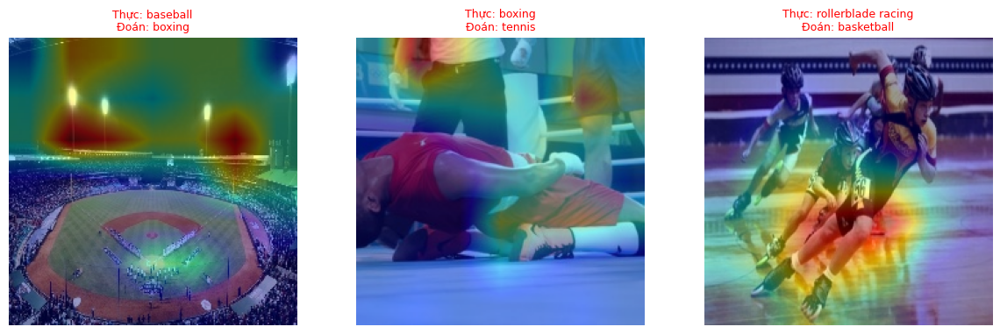

In [37]:
def gradcam_misclassified(model, ds_raw, preprocess_fn, class_names, max_show=8, cols=4):
    """Grad-CAM cho các ảnh test bị đoán SAI -> dùng cho phần phân tích lỗi trong báo cáo."""
    last_conv_name = get_last_conv_layer_name(model)
    imgs = np.concatenate([images.numpy() for images, _ in ds_raw])
    labs = np.concatenate([labels.numpy() for _, labels in ds_raw])
    x_all = preprocess_fn(tf.constant(imgs)) if preprocess_fn else tf.constant(imgs)
    preds = np.argmax(model.predict(x_all, batch_size=32, verbose=0), axis=1)
    wrong = np.where(preds != labs)[0]
    print(f"Số ảnh test bị đoán sai: {len(wrong)}/{len(labs)}")
    if len(wrong) == 0:
        return
    wrong = wrong[:max_show]
    rows = math.ceil(len(wrong) / cols)
    plt.figure(figsize=(4 * cols, 3.8 * rows))
    for k, idx in enumerate(wrong):
        x = tf.expand_dims(x_all[idx], 0)
        hm, p = make_gradcam_heatmap(x, model, last_conv_name)
        plt.subplot(rows, cols, k + 1)
        plt.imshow(overlay_gradcam(imgs[idx].astype("uint8"), hm))
        plt.axis("off")
        plt.title(f"Thực: {class_names[labs[idx]]}\nĐoán: {class_names[p]}", color="red", fontsize=9)
    plt.tight_layout()
    plt.show()

print("Grad-CAM — các ảnh MobileNetV2 đoán sai:")
gradcam_misclassified(mobilenet_model, test_ds_raw, mnv2_preprocess, CLASS_NAMES)


## 9. Lưu mô hình & kết luận

Mô hình tốt nhất (chọn theo **Validation Accuracy**, không chọn theo test để tránh "nhìn trộm" tập test) được lưu lại để dùng cho ứng dụng demo (web/mobile) phân loại môn thể thao từ ảnh chụp/tải lên.


In [39]:
for m in (cnn_scratch, mobilenet_model, resnet_model):
    m.compile(optimizer="adam", loss=make_loss(), metrics=["accuracy"])

In [40]:
# Chọn mô hình tốt nhất theo VALIDATION accuracy (không dùng test để chọn -> tránh rò rỉ thông tin từ tập test).
val_pairs = {
    "CNN_Scratch": (cnn_scratch, valid_ds),
    "MobileNetV2": (mobilenet_model, valid_ds_mnv2),
    "ResNet50":    (resnet_model, valid_ds_res),
}
val_acc = {n: m.evaluate(ds, verbose=0)[1] for n, (m, ds) in val_pairs.items()}
summary_df["Val Accuracy"] = summary_df["Mô hình"].map(val_acc).round(4)

# Nếu hòa, max() lấy mô hình đứng trước trong dict. Val chỉ 100 ảnh nên dễ hòa -> xem thêm kết quả K-Fold (mục 7c).
best_model_name = max(val_acc, key=val_acc.get)
model_map = {"CNN_Scratch": cnn_scratch, "MobileNetV2": mobilenet_model, "ResNet50": resnet_model}
best_model = model_map[best_model_name]
best_model.save("sportsnap_best_model.keras")
print(f"Đã lưu mô hình tốt nhất (theo Val): {best_model_name} -> sportsnap_best_model.keras")
print(summary_df)


Đã lưu mô hình tốt nhất (theo Val): MobileNetV2 -> sportsnap_best_model.keras
       Mô hình  Test Accuracy  Đạt mục tiêu (>=0.88)  Val Accuracy
0     ResNet50           1.00                   True          0.97
1  MobileNetV2           0.97                   True          0.98
2  CNN_Scratch           0.80                  False          0.05


### Hàm dự đoán ảnh đơn (`predict_image`)

In [41]:
def predict_image(path, model, preprocess_fn, class_names, top_k=3, tta=True):
    """Dự đoán 1 ảnh: hiển thị ảnh + top_k nhãn (kèm xác suất) làm tiêu đề, trả về nhãn dự đoán.
    tta=True: lấy trung bình dự đoán của ảnh gốc và ảnh lật ngang (Test-Time Augmentation) cho ổn định hơn."""
    img = tf.keras.utils.load_img(path, target_size=IMG_SIZE)   # tự chuyển về RGB 224x224
    arr = tf.keras.utils.img_to_array(img)
    batch = np.stack([arr, arr[:, ::-1, :]]) if tta else np.expand_dims(arr, 0)
    # CNN_Scratch (preprocess_fn=None) đã có Rescaling(1/255) bên trong -> KHÔNG chia 255 thêm lần nữa
    x = preprocess_fn(batch.copy()) if preprocess_fn else batch
    probs = model.predict(x, verbose=0).mean(axis=0)
    idx = np.argsort(probs)[::-1][:top_k]
    plt.figure()
    plt.imshow(img)
    plt.axis("off")
    plt.title("\n".join(f"{class_names[i]}: {probs[i] * 100:.1f}%" for i in idx))
    plt.show()
    return class_names[idx[0]]


Ảnh thật: basketball | Đường dẫn: /kaggle/input/datasets/kienmaitrung287/data-sportsnap/datasets/sports-classification/test/basketball/1.jpg


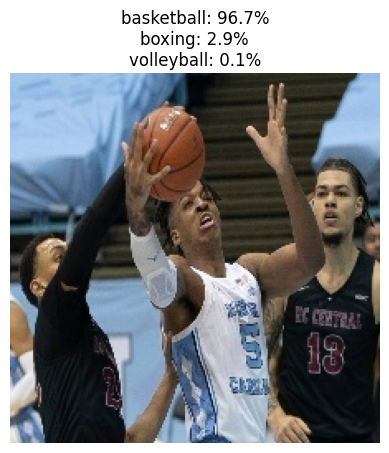

Dự đoán: basketball


In [42]:
import random

# Chọn preprocess_fn tương ứng với best_model đã lưu (dựa theo summary_df)
preprocess_map = {
    "CNN_Scratch": None,
    "MobileNetV2": mnv2_preprocess,
    "ResNet50": resnet_preprocess,
}
best_preprocess_fn = preprocess_map[best_model_name]

# Lấy ngẫu nhiên 1 ảnh thật từ tập test để thử
sample_class = random.choice(CLASS_NAMES)
sample_files = glob.glob(os.path.join(TEST_DIR, sample_class, "*"))
sample_path = random.choice(sample_files)

print(f"Ảnh thật: {sample_class} | Đường dẫn: {sample_path}")
pred = predict_image(sample_path, best_model, best_preprocess_fn, CLASS_NAMES)
print("Dự đoán:", pred)

[SportSnap] Thư mục ảnh kiểm tra riêng: /kaggle/input/datasets/kienmaitrung287/data-sportsnap/datasets/anh-ngoai
[SportSnap] Tìm thấy 100 ảnh trong '/kaggle/input/datasets/kienmaitrung287/data-sportsnap/datasets/anh-ngoai'.
--- archery/1.jpg ---


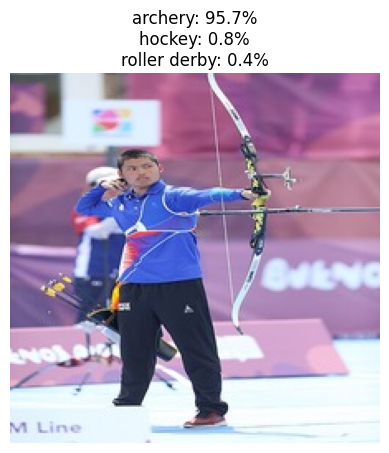

Dự đoán: archery
--- archery/2.jpg ---


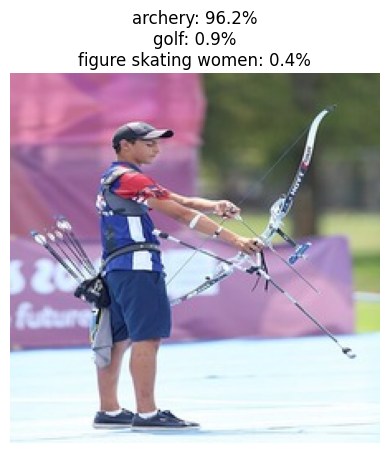

Dự đoán: archery
--- archery/3.jpg ---


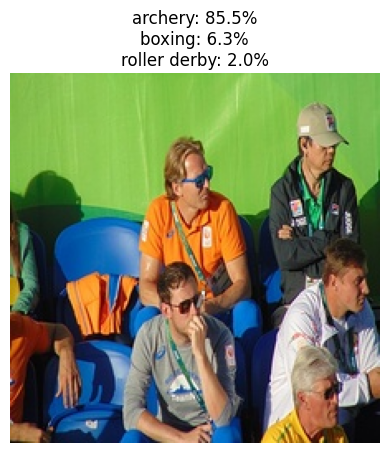

Dự đoán: archery
--- archery/4.jpg ---


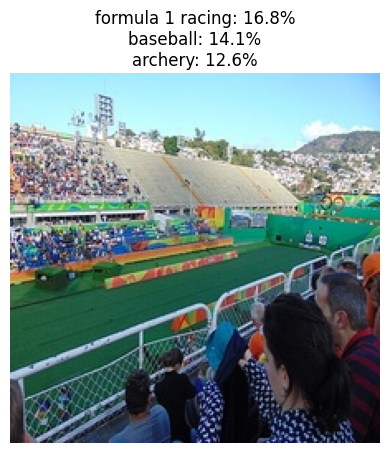

Dự đoán: formula 1 racing
--- archery/5.jpg ---


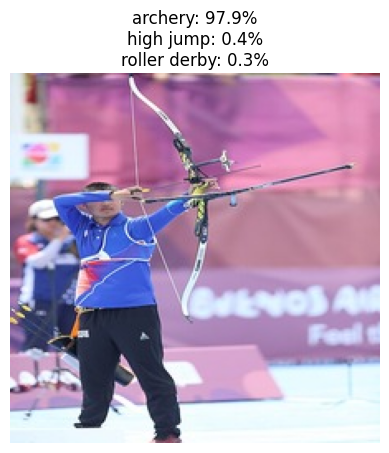

Dự đoán: archery
--- baseball/1.jpg ---


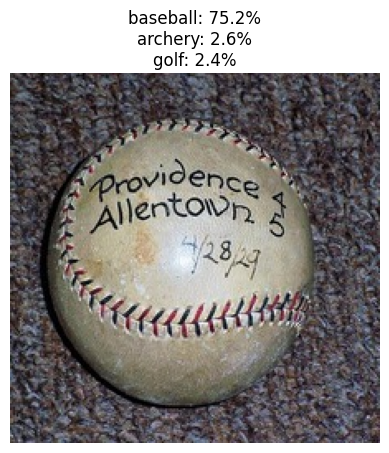

Dự đoán: baseball
--- baseball/2.jpg ---


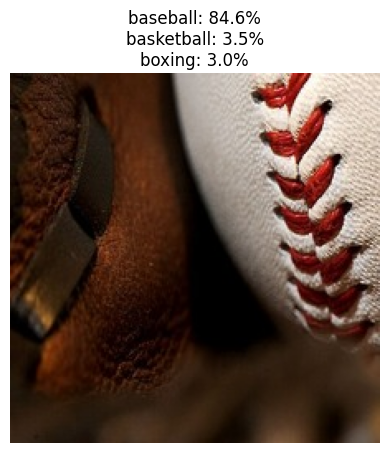

Dự đoán: baseball
--- baseball/3.jpg ---


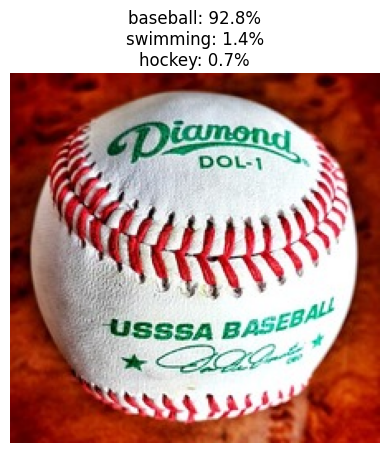

Dự đoán: baseball
--- baseball/4.jpg ---


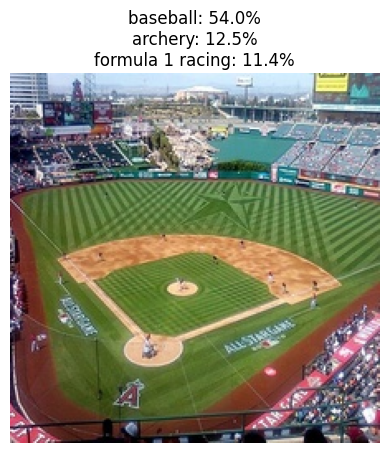

Dự đoán: baseball
--- baseball/5.jpg ---


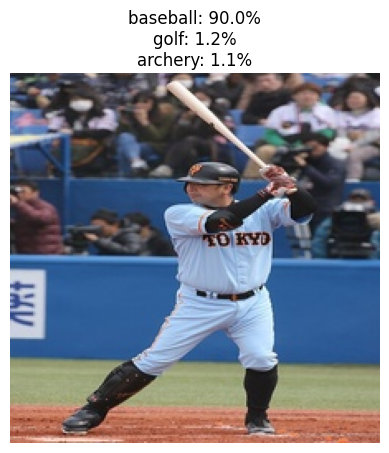

Dự đoán: baseball
--- basketball/1.jpg ---


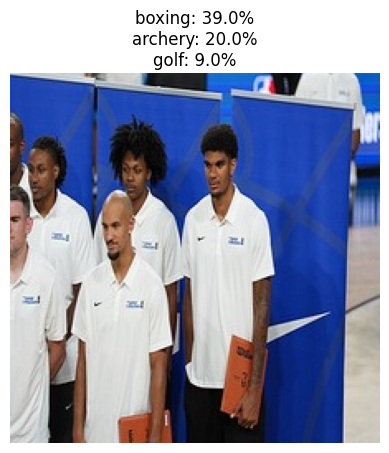

Dự đoán: boxing
--- basketball/2.jpg ---


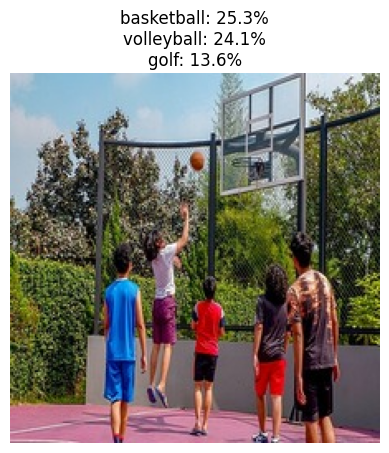

Dự đoán: basketball
--- basketball/3.jpg ---


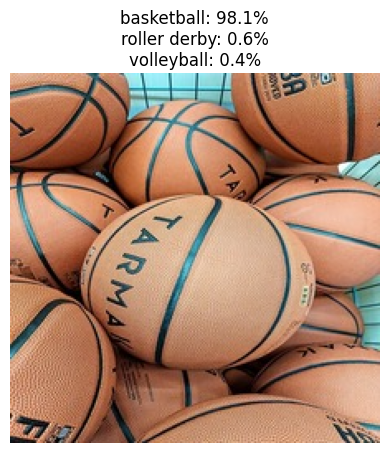

Dự đoán: basketball
--- basketball/4.jpg ---


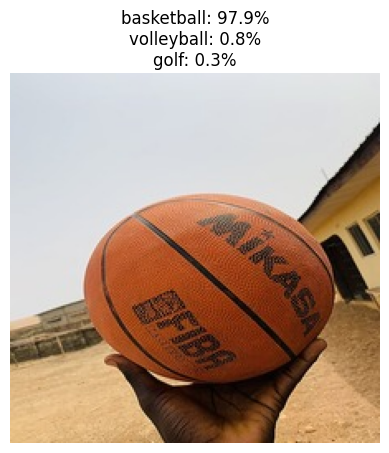

Dự đoán: basketball
--- basketball/5.jpg ---


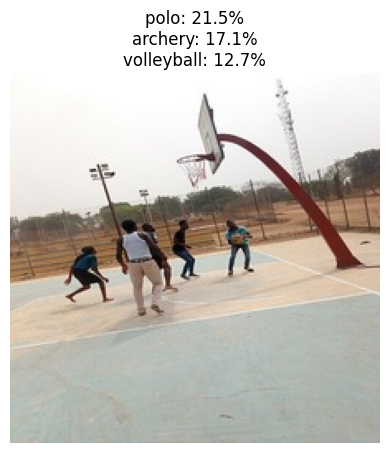

Dự đoán: polo


In [43]:
import os

def auto_find_upload_dir():
    if os.path.exists("/kaggle/input"):
        for root, dirs, _ in os.walk("/kaggle/input"):
            if "anh-ngoai" in dirs:
                return os.path.join(root, "anh-ngoai")
            if os.path.basename(root).lower() in ["anh-ngoai", "data123"]:
                return root
    cands = [
        r"d:\tgmt\datasets\anh-ngoai",
        r"../datasets/anh-ngoai",
        "/kaggle/input/anh-ngoai",
        "/kaggle/input/datasets/kienmaitrung287/data123",
    ]
    for p in cands:
        if os.path.exists(p):
            return p
    return cands[0]

UPLOAD_DIR = auto_find_upload_dir()
print(f"[SportSnap] Thư mục ảnh kiểm tra riêng: {UPLOAD_DIR}")

valid_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

if os.path.exists(UPLOAD_DIR):
    all_image_paths = []
    for root, _, files in os.walk(UPLOAD_DIR):
        for fname in sorted(files):
            if fname.lower().endswith(valid_extensions):
                all_image_paths.append(os.path.join(root, fname))
    
    print(f"[SportSnap] Tìm thấy {len(all_image_paths)} ảnh trong '{UPLOAD_DIR}'.")
    for path in all_image_paths[:15]:
        rel = os.path.relpath(path, UPLOAD_DIR)
        print(f"--- {rel} ---")
        pred = predict_image(path, best_model, best_preprocess_fn, CLASS_NAMES)
        print("Dự đoán:", pred)
else:
    print(f"Thư mục '{UPLOAD_DIR}' không tồn tại. Bỏ qua bước kiểm tra ảnh upload riêng.")


## 10. Hướng phát triển sau đồ án (tiến tới NCKH cấp Khoa)

- **Explainability nâng cao**: bổ sung phân tích SHAP bên cạnh Grad-CAM để so sánh và củng cố kết luận về đặc trưng thị giác quan trọng (màu sân, trang phục, dụng cụ...).
- **Mở rộng sang video**: áp dụng mô hình theo frame + tổng hợp theo temporal (vd. majority voting hoặc 3D-CNN/temporal pooling) để phân loại môn thể thao từ video thay vì ảnh tĩnh.
- **Viết báo cáo phân tích explainability** tổng hợp kết quả Grad-CAM/SHAP, phù hợp nộp NCKH cấp Khoa.
- **Triển khai demo**: đóng gói `sportsnap_best_model.keras` vào ứng dụng web (Streamlit/Flask) hoặc mobile (TensorFlow Lite) để chụp/tải ảnh và nhận kết quả phân loại trực tiếp.

**Từ khóa:** Sports Image Classification; Transfer Learning; CNN; MobileNetV2


## 11. Số liệu bổ sung: số tham số, kích thước mô hình, thời gian suy luận

In [44]:
# ==== Số liệu bổ sung cho báo cáo: số tham số, kích thước tệp, thời gian suy luận ====
import time

print("Số tham số:")
for n, m in model_map.items():
    print(f"  {n}: {m.count_params():,}")

size_mb = os.path.getsize("sportsnap_best_model.keras") / 1e6
print(f"Kích thước sportsnap_best_model.keras: {size_mb:.1f} MB")

x_dummy = np.random.rand(1, IMG_SIZE[0], IMG_SIZE[1], 3).astype("float32") * 255.0
best_model.predict(x_dummy, verbose=0)          # khởi động (warm-up)
t0 = time.time()
for _ in range(50):
    best_model.predict(x_dummy, verbose=0)
print(f"Thời gian suy luận trung bình: {(time.time() - t0) / 50 * 1000:.1f} ms/ảnh "
      f"(thiết bị: {'GPU' if tf.config.list_physical_devices('GPU') else 'CPU'})")

Số tham số:
  CNN_Scratch: 646,548
  MobileNetV2: 2,283,604
  ResNet50: 23,628,692
Kích thước sportsnap_best_model.keras: 9.7 MB
Thời gian suy luận trung bình: 105.3 ms/ảnh (thiết bị: GPU)


In [45]:
import os, json, shutil

OUT = "/kaggle/working/sportsnap_model" if os.path.exists("/kaggle/working") else r"d:\tgmt\all_sportsnap_outputs\sportsnap_model"
os.makedirs(OUT, exist_ok=True)

shutil.copy("sportsnap_best_model.keras", OUT)
json.dump(CLASS_NAMES, open(f"{OUT}/class_names.json", "w"), ensure_ascii=False)
summary_df.to_csv(f"{OUT}/summary.csv", index=False)

json.dump({
    "title": "SportSnap Model",
    "id": "kienmaitrung287/sportsnap-model",   # username/slug
    "licenses": [{"name": "CC0-1.0"}]
}, open(f"{OUT}/dataset-metadata.json", "w"))
print(f"Đã xuất artifacts model vào: {OUT}")


Đã xuất artifacts model vào: /kaggle/working/sportsnap_model


In [46]:
import os
search_root = "/kaggle/input" if os.path.exists("/kaggle/input") else r"d:\tgmt"
for root, dirs, files in os.walk(search_root):
    for f in files:
        if f.endswith((".keras", ".json")) and ("sportsnap" in (root + f).lower() or f.endswith(".keras")):
            print(os.path.join(root, f))


/kaggle/input/models/kienmaitrung287/sportsnap-model/keras/default/1/kaggle/working/sportsnap_model/sportsnap_best_model.keras
/kaggle/input/models/kienmaitrung287/sportsnap-model/keras/default/1/kaggle/working/sportsnap_model/dataset-metadata.json
/kaggle/input/models/kienmaitrung287/sportsnap-model/keras/default/1/kaggle/working/sportsnap_model/class_names.json


In [47]:
import os, json, subprocess, shutil

try:
    from kaggle_secrets import UserSecretsClient
    USERNAME = "kienmaitrung287"
    SLUG = "sportsnap-model"
    OUT = "/kaggle/working/sportsnap_model" if os.path.exists("/kaggle/working") else r"d:\tgmt\all_sportsnap_outputs\sportsnap_model"

    # 1) Gom file cần lưu vào một thư mục
    assert os.path.exists("sportsnap_best_model.keras"), "Chưa có file model: hãy chạy cell lưu model trước"
    os.makedirs(OUT, exist_ok=True)
    shutil.copy("sportsnap_best_model.keras", OUT)
    json.dump(CLASS_NAMES, open(f"{OUT}/class_names.json", "w"), ensure_ascii=False)
    summary_df.to_csv(f"{OUT}/summary.csv", index=False)
    json.dump({
        "title": "SportSnap Model",
        "id": f"{USERNAME}/{SLUG}",
        "licenses": [{"name": "CC0-1.0"}],
    }, open(f"{OUT}/dataset-metadata.json", "w"))

    # 2) Khai báo tài khoản Kaggle
    os.environ["KAGGLE_USERNAME"] = USERNAME
    os.environ["KAGGLE_KEY"] = UserSecretsClient().get_secret("KAGGLE_KEY")

    # 3) Đẩy lên: tạo mới, nếu dataset đã tồn tại thì tạo phiên bản mới
    r = subprocess.run(["kaggle", "datasets", "create", "-p", OUT], capture_output=True, text=True)
    print(r.stdout, r.stderr)
    if "already" in (r.stdout + r.stderr).lower():
        r = subprocess.run(["kaggle", "datasets", "version", "-p", OUT, "-m", "cap nhat model"],
                           capture_output=True, text=True)
        print(r.stdout, r.stderr)
except Exception as e:
    print(f"[Bỏ qua khi chạy máy local / không có Kaggle Secrets]: {e}")


[Bỏ qua khi chạy máy local / không có Kaggle Secrets]: Unexpected response from the service. Response: {'errors': ['No user secrets exist for kernel id 143456457 and label KAGGLE_KEY.'], 'error': {'code': 5}, 'wasSuccessful': False}.


Found 6000 files belonging to 20 classes.
Found 100 files belonging to 20 classes.
Found 100 files belonging to 20 classes.
       so_anh  so_dung  accuracy
split                           
test      100       97    0.9700
train    6000     5960    0.9933
valid     100       98    0.9800
Đã lưu kết quả phân tích tất cả ảnh ra: /kaggle/working/ket_qua_du_doan_tat_ca_anh.csv

Tổng số ảnh sai: 45/6200
split                               file              thuc_te              du_doan  do_tin_cay        du_doan_thu_2
train              train/archery/081.jpg              archery                 golf   33.700001              archery
train              train/archery/082.jpg              archery             baseball   33.099998              archery
train             train/baseball/298.jpg             baseball               boxing   31.799999             baseball
train           train/basketball/002.jpg           basketball             baseball   57.000000           basketball
train           tr

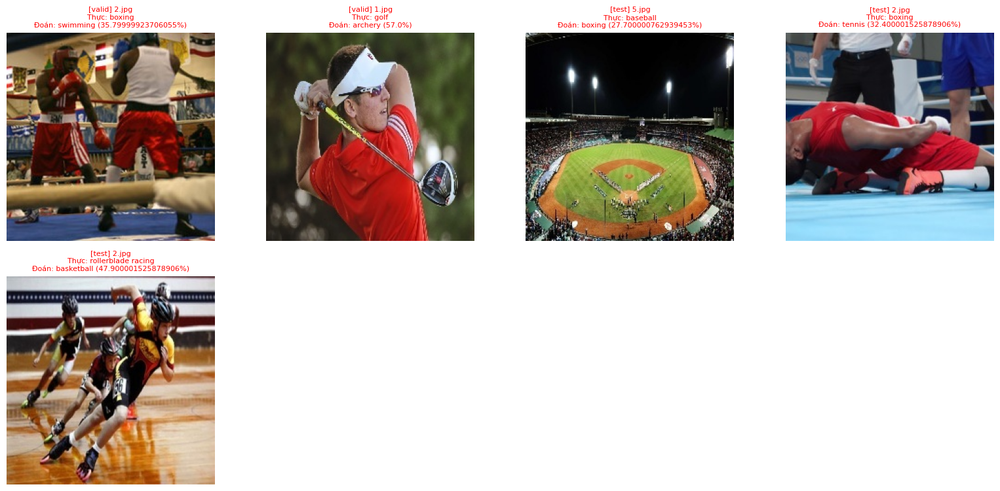

In [48]:
import math

def predict_all(model, preprocess_fn, directory, split_name):
    # shuffle=False nên thứ tự file_paths khớp với thứ tự dự đoán
    ds = make_filtered_dataset(directory, SELECTED_CLASSES, shuffle=False)
    paths = list(ds.file_paths)
    y_true = np.concatenate([y.numpy() for _, y in ds])
    ds_in = ds.map(lambda x, y: (preprocess_fn(x), y)) if preprocess_fn else ds
    probs = model.predict(ds_in, verbose=0)
    order = np.argsort(-probs, axis=1)
    top1, top2 = order[:, 0], order[:, 1]
    return pd.DataFrame({
        "split": split_name,
        "file": [os.path.relpath(p, DATA_ROOT) for p in paths],
        "path": paths,
        "thuc_te": [CLASS_NAMES[i] for i in y_true],
        "du_doan": [CLASS_NAMES[i] for i in top1],
        "do_tin_cay": (probs[np.arange(len(probs)), top1] * 100).round(1),
        "du_doan_thu_2": [CLASS_NAMES[i] for i in top2],
        "dung": top1 == y_true,
    })

# 1) Chạy trên TOÀN BỘ ảnh: train + valid + test
df_all = pd.concat(
    [predict_all(best_model, best_preprocess_fn, d, s)
     for s, d in [("train", TRAIN_DIR), ("valid", VALID_DIR), ("test", TEST_DIR)]],
    ignore_index=True)

# 2) Accuracy từng tập
summary = df_all.groupby("split")["dung"].agg(so_anh="count", so_dung="sum")
summary["accuracy"] = (summary["so_dung"] / summary["so_anh"]).round(4)
print(summary)

# 3) Lưu kết quả TẤT CẢ ảnh ra CSV (có thể tải về hoặc mở bằng Excel)
csv_out = "/kaggle/working/ket_qua_du_doan_tat_ca_anh.csv" if os.path.exists("/kaggle/working") else r"d:\tgmt\all_sportsnap_outputs\ket_qua_du_doan_tat_ca_anh.csv"
df_all.drop(columns="path").to_csv(csv_out, index=False)
print(f"Đã lưu kết quả phân tích tất cả ảnh ra: {csv_out}")

# 4) Danh sách ảnh bị đoán sai (kèm tên file)
wrong_df = df_all[~df_all["dung"]]
print(f"\nTổng số ảnh sai: {len(wrong_df)}/{len(df_all)}")
print(wrong_df.drop(columns=["path", "dung"]).to_string(index=False))

# 5) Hiển thị ảnh sai của valid + test
def show_wrong(df, max_show=40, cols=4):
    df = df.head(max_show)
    if len(df) == 0:
        print("Không có ảnh sai nào.")
        return
    rows = math.ceil(len(df) / cols)
    plt.figure(figsize=(4 * cols, 3.8 * rows))
    for k, r in enumerate(df.itertuples()):
        plt.subplot(rows, cols, k + 1)
        plt.imshow(tf.keras.utils.load_img(r.path, target_size=IMG_SIZE))
        plt.axis("off")
        plt.title(f"[{r.split}] {os.path.basename(r.file)}\nThực: {r.thuc_te}\n"
                  f"Đoán: {r.du_doan} ({r.do_tin_cay}%)", color="red", fontsize=8)
    plt.tight_layout()
    plt.show()

show_wrong(wrong_df[wrong_df["split"] != "train"])


In [49]:
sus = df_all[(df_all.split == "train") & (~df_all.dung) & (df_all.do_tin_cay >= 80)]
print(len(sus))
print(sus[["file", "thuc_te", "du_doan", "do_tin_cay"]].to_string(index=False))
show_wrong(sus, max_show=24)

0
Empty DataFrame
Columns: [file, thuc_te, du_doan, do_tin_cay]
Index: []
Không có ảnh sai nào.


## 12. Các thí nghiệm bổ sung & kiểm chứng nâng cao (Mục 5.9)

Gộp toàn bộ thí nghiệm từ `detainhom_bosung.ipynb` để phục vụ điền số liệu Bảng 5.10 và phân tích sâu:
- Các mục **12.1, 12.2** sử dụng trực tiếp `train_transfer_model`, `build_cnn_scratch` (từ Mục 5–6) và cờ `RUN_*` ở Mục 2.
- Các mục **12.3–12.7** tự động dùng model đang có trong bộ nhớ (nếu vừa chạy Mục 6–9) hoặc nạp từ checkpoint `.keras` đã lưu (`all_sportsnap_outputs/`, `notebook/`, `backend/models/`). Nếu chạy nhảy cóc chỉ các mục đánh giá nhanh này, hãy chạy trước tối thiểu Mục **1, 2, 4 và 8**.

In [16]:
# ==== HÀM HỖ TRỢ DÙNG CHUNG CHO MỤC 12 ====
VALID_IMAGE_EXTS = (".jpg", ".jpeg", ".png", ".webp", ".bmp")

def set_seed(s):
    random.seed(s)
    np.random.seed(s)
    tf.random.set_seed(s)

def eval_ds(model, ds_raw, pre=None):
    ds = prep_dataset(ds_raw, augment=False, preprocess_fn=pre, cache=False)
    y = np.concatenate([b.numpy() for _, b in ds_raw])
    p = np.argmax(model.predict(ds, verbose=0), axis=1)
    return accuracy_score(y, p), f1_score(y, p, average="macro")

def resolve_model_path(filenames):
    search_dirs = [
        ".",
        "/kaggle/working",
        MODEL_DIR,                                  # thêm dòng này
        r"d:\tgmt\all_sportsnap_outputs",
        r"../all_sportsnap_outputs",
        r"d:\tgmt\notebook",
        r"d:\tgmt\backend\models",
        r"../backend/models",
    ]
    for d in search_dirs:
        for fn in filenames:
            p = os.path.join(d, fn)
            if os.path.exists(p):
                return p
    return None

def warn_if_label_mismatch(model_path):
    model_dir = os.path.dirname(os.path.abspath(model_path))
    for lbl_cand in [
        os.path.join(model_dir, "labels.json"),
        os.path.join(model_dir, "class_names.json"),
        os.path.join(model_dir, "sportsnap_model", "class_names.json"),
    ]:
        if os.path.exists(lbl_cand):
            with open(lbl_cand, "r", encoding="utf-8") as f:
                ckpt_labels = json.load(f)
            if list(ckpt_labels) != list(CLASS_NAMES):
                diff_ckpt = sorted(set(ckpt_labels) - set(CLASS_NAMES))
                diff_curr = sorted(set(CLASS_NAMES) - set(ckpt_labels))
                print(
                    f"[Cảnh báo] Checkpoint '{model_path}' dùng bộ nhãn khác với CLASS_NAMES hiện tại! "
                    f"(Thừa trong checkpoint: {diff_ckpt}; mới trong dataset: {diff_curr}). "
                    "Hãy chạy Mục 6–9 để huấn luyện lại model cho bộ dữ liệu mới."
                )
            return

def get_or_load_best_model():
    if "best_model" in globals() and globals()["best_model"] is not None:
        pre = globals()["best_preprocess_fn"] if "best_preprocess_fn" in globals() else mnv2_preprocess
        name = globals().get("best_model_name", "MobileNetV2")
        return globals()["best_model"], pre, name

    p = resolve_model_path(["sportsnap_best_model.keras", "best_model.keras", "MobileNetV2_finetune_best.keras"])
    if p is None:
        raise FileNotFoundError("Không tìm thấy file model đã lưu (sportsnap_best_model.keras / best_model.keras).")
    print(f"[SportSnap] Nạp model tốt nhất từ: {p}")
    warn_if_label_mismatch(p)
    return tf.keras.models.load_model(p, compile=False), mnv2_preprocess, "MobileNetV2 (loaded)"

def get_or_load_named_model(var_name, checkpoint_filenames, require_history_key=None):
    has_trained = True
    if require_history_key is not None:
        has_trained = "histories" in globals() and require_history_key in globals()["histories"]
    if has_trained and var_name in globals() and globals()[var_name] is not None:
        return globals()[var_name]
    p = resolve_model_path(checkpoint_filenames)
    if p is not None:
        print(f"[SportSnap] Nạp {var_name} từ checkpoint: {p}")
        warn_if_label_mismatch(p)
        return tf.keras.models.load_model(p, compile=False)
    return None

### 12.1. Lặp nhiều hạt giống (MobileNetV2: 5 seed; ResNet50: 3 seed; CNN_Scratch: 5 seed)

In [1]:
import glob, os
MODEL_DIR = os.path.dirname(glob.glob("/kaggle/input/**/MobileNetV2_finetune_best.keras", recursive=True)[0])
print(MODEL_DIR)

/kaggle/input/models/kienmaitrung287/sportsnap/tensorflow2/default/1


In [19]:
WORK = MODEL_DIR

cnn_scratch     = keras.models.load_model(f"{WORK}/cnn_scratch_best.keras", compile=False)
mobilenet_model = keras.models.load_model(f"{WORK}/MobileNetV2_finetune_best.keras", compile=False)
resnet_model    = keras.models.load_model(f"{WORK}/ResNet50_finetune_best.keras", compile=False)

test_ds       = prep_dataset(test_ds_raw, augment=False)
test_ds_mnv2  = prep_dataset(test_ds_raw, augment=False, preprocess_fn=mnv2_preprocess)
test_ds_res   = prep_dataset(test_ds_raw, augment=False, preprocess_fn=resnet_preprocess)
valid_ds      = prep_dataset(valid_ds_raw, augment=False, onehot=True)
valid_ds_mnv2 = prep_dataset(valid_ds_raw, augment=False, preprocess_fn=mnv2_preprocess, onehot=True)
valid_ds_res  = prep_dataset(valid_ds_raw, augment=False, preprocess_fn=resnet_preprocess, onehot=True)

for m in (cnn_scratch, mobilenet_model, resnet_model):
    m.compile(optimizer="adam", loss=make_loss(), metrics=["accuracy"])

histories, head_only_acc = {}, {}
for name, ds in [("MobileNetV2", test_ds_mnv2), ("ResNet50", test_ds_res)]:
    m = keras.models.load_model(f"{WORK}/{name}_head_best.keras", compile=False)
    head_only_acc[name] = quick_acc(m, ds)
print(head_only_acc)

{'MobileNetV2': 0.94, 'ResNet50': 0.93}


In [20]:
if RUN_MULTI_SEED:
    # Đồng bộ lại dataset để mỗi seed không dùng nhầm iterator cũ
    ms_train_raw = make_filtered_dataset(TRAIN_DIR, SELECTED_CLASSES, shuffle=True)
    ms_valid_raw = make_filtered_dataset(VALID_DIR, SELECTED_CLASSES, shuffle=False)
    ms_test_raw  = make_filtered_dataset(TEST_DIR, SELECTED_CLASSES, shuffle=False)

    CFG_SEEDS = {
        "MobileNetV2": (MobileNetV2, mnv2_preprocess, 5),
        "ResNet50":    (ResNet50, resnet_preprocess, 3),
    }
    multi_seed_res = {}
    for name, (cls, pre, n_seed) in CFG_SEEDS.items():
        multi_seed_res[name] = []
        for s in range(n_seed):
            set_seed(100 + s)
            m, *_ = train_transfer_model(
                cls, pre, f"{name}_s{s}",
                ms_train_raw, ms_valid_raw, UNFREEZE[name],
                checkpoint=False,
                epochs_head=SUPP_EPOCHS_HEAD,
                epochs_ft=SUPP_EPOCHS_FT,
                verbose=0,
            )
            acc, f1 = eval_ds(m, ms_test_raw, pre)
            multi_seed_res[name].append((acc, f1))
            print(f"{name} seed={100+s}: acc={acc:.4f}, F1={f1:.4f}")
            del m
            keras.backend.clear_session()
            gc.collect()

    for k, v in multi_seed_res.items():
        a = np.array(v)
        print(
            f"{k}: acc {a[:,0].mean():.3f} ± {a[:,0].std(ddof=1):.3f} "
            f"(min {a[:,0].min():.2f}, max {a[:,0].max():.2f}) | "
            f"F1 {a[:,1].mean():.3f} ± {a[:,1].std(ddof=1):.3f}"
        )
else:
    print("RUN_MULTI_SEED = False -> bỏ qua thí nghiệm lặp nhiều hạt giống. Bật RUN_MULTI_SEED = True ở mục 2 để chạy.")

Found 6000 files belonging to 20 classes.
Found 100 files belonging to 20 classes.
Found 100 files belonging to 20 classes.
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()
E0000 00:00:1794394753.627567     151 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


MobileNetV2 seed=100: acc=0.9800, F1=0.9798


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


MobileNetV2 seed=101: acc=0.9700, F1=0.9698


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


... (7 outputs left out)

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


ResNet50 seed=101: acc=0.9800, F1=0.9806


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


ResNet50 seed=102: acc=0.9800, F1=0.9798
MobileNetV2: acc 0.970 ± 0.012 (min 0.95, max 0.98) | F1 0.970 ± 0.012
ResNet50: acc 0.983 ± 0.006 (min 0.98, max 0.99) | F1 0.983 ± 0.006


#### CNN_Scratch (5 seed, mỗi seed 50 epoch)
Dùng lại kiến trúc `build_cnn_scratch` và lịch cosine LR của Mục 6 với `set_seed(100 + s)` (bật `RUN_MULTI_SEED = True` và `RUN_MULTI_SEED_CNN = True` ở Mục 2 để chạy).

In [21]:
if RUN_MULTI_SEED and RUN_MULTI_SEED_CNN:
    ms_train_raw = globals().get("ms_train_raw") or make_filtered_dataset(TRAIN_DIR, SELECTED_CLASSES, shuffle=True)
    ms_valid_raw = globals().get("ms_valid_raw") or make_filtered_dataset(VALID_DIR, SELECTED_CLASSES, shuffle=False)
    ms_test_raw  = globals().get("ms_test_raw")  or make_filtered_dataset(TEST_DIR, SELECTED_CLASSES, shuffle=False)

    n_epochs_cnn = globals().get("EPOCHS_SCRATCH", 50)
    cnn_seed_res = []
    for s in range(5):
        set_seed(100 + s)
        m_cnn = build_cnn_scratch(INPUT_SHAPE, NUM_CLASSES)
        tr_c = prep_dataset(ms_train_raw, augment=True, onehot=True)
        va_c = prep_dataset(ms_valid_raw, augment=False, onehot=True)
        m_cnn.compile(optimizer=keras.optimizers.Adam(1e-3), loss=make_loss(), metrics=["accuracy"])
        m_cnn.fit(
            tr_c, validation_data=va_c, epochs=n_epochs_cnn, verbose=0,
            callbacks=get_callbacks(
                f"cnn_scratch_s{s}", checkpoint=False, plateau=False,
                lr_fn=cosine_schedule(1e-3, n_epochs_cnn, min_lr=1e-6, warmup_epochs=2),
                patience=12,
            ),
        )
        acc, f1 = eval_ds(m_cnn, ms_test_raw, None)
        cnn_seed_res.append((acc, f1))
        print(f"CNN_Scratch seed={100+s}: acc={acc:.4f}, F1={f1:.4f}")
        del m_cnn, tr_c, va_c
        keras.backend.clear_session()
        gc.collect()

    a_cnn = np.array(cnn_seed_res)
    print(
        f"CNN_Scratch: acc {a_cnn[:,0].mean():.3f} ± {a_cnn[:,0].std(ddof=1):.3f} "
        f"(min {a_cnn[:,0].min():.2f}, max {a_cnn[:,0].max():.2f}) | "
        f"F1 {a_cnn[:,1].mean():.3f} ± {a_cnn[:,1].std(ddof=1):.3f}"
    )
else:
    print("Bỏ qua CNN_Scratch multi-seed (cần bật cả RUN_MULTI_SEED = True và RUN_MULTI_SEED_CNN = True ở mục 2).")

E0000 00:00:1794408370.223582     148 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794408374.664989     148 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794408427.728045     150 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794408429.274919     150 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at l

CNN_Scratch seed=100: acc=0.8100, F1=0.8010


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


CNN_Scratch seed=101: acc=0.7900, F1=0.7528


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


CNN_Scratch seed=102: acc=0.8800, F1=0.8739


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


CNN_Scratch seed=103: acc=0.8100, F1=0.7794


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


CNN_Scratch seed=104: acc=0.8000, F1=0.7798
CNN_Scratch: acc 0.818 ± 0.036 (min 0.79, max 0.88) | F1 0.797 ± 0.046


### 12.2. Tập test mở rộng (20% train, phân tầng); huấn luyện trên 80% còn lại

In [22]:
if RUN_EXTENDED_TEST:
    ext_paths, ext_labels = [], []
    for i, c in enumerate(CLASS_NAMES):
        fs = sorted(
            f for f in glob.glob(os.path.join(TRAIN_DIR, c, "*"))
            if f.lower().endswith(VALID_IMAGE_EXTS)
        )
        ext_paths += fs
        ext_labels += [i] * len(fs)

    p_tr, p_te, y_tr, y_te = train_test_split(
        ext_paths, ext_labels, test_size=0.2, stratify=ext_labels, random_state=SEED
    )
    print(f"Chia phân tầng từ train -> Train 80%: {len(p_tr)} ảnh | Test mở rộng 20%: {len(p_te)} ảnh")

    def to_ds(paths_list, labels_list, shuffle=False):
        def load(p, y):
            img = tf.io.decode_image(tf.io.read_file(p), channels=3, expand_animations=False)
            img = tf.image.resize(img, IMG_SIZE)
            img.set_shape(IMG_SIZE + (3,))
            return img, y
        ds = tf.data.Dataset.from_tensor_slices((paths_list, labels_list)).map(load, num_parallel_calls=AUTOTUNE)
        if shuffle:
            ds = ds.shuffle(len(paths_list), seed=SEED)
        return ds.batch(BATCH_SIZE)

    tr80, te20 = to_ds(p_tr, y_tr, True), to_ds(p_te, y_te, False)
    set_seed(SEED)
    m_ext, *_ = train_transfer_model(
        MobileNetV2, mnv2_preprocess, "MNV2_ext",
        tr80, valid_ds_raw, UNFREEZE["MobileNetV2"],
        checkpoint=False,
        epochs_head=SUPP_EPOCHS_HEAD,
        epochs_ft=SUPP_EPOCHS_FT,
        verbose=0,
    )
    acc, f1 = eval_ds(m_ext, te20, mnv2_preprocess)
    n_te, z = len(y_te), 1.96
    lo = (acc + z*z/(2*n_te) - z*np.sqrt(acc*(1-acc)/n_te + z*z/(4*n_te*n_te))) / (1 + z*z/n_te)
    hi = (acc + z*z/(2*n_te) + z*np.sqrt(acc*(1-acc)/n_te + z*z/(4*n_te*n_te))) / (1 + z*z/n_te)
    print(f"Test mở rộng n={n_te}: acc {acc:.3f} | F1 {f1:.3f} | Wilson 95% CI [{lo:.3f}; {hi:.3f}]")
    del m_ext, tr80, te20
    keras.backend.clear_session()
    gc.collect()
else:
    print("RUN_EXTENDED_TEST = False -> bỏ qua thí nghiệm tập test mở rộng. Bật RUN_EXTENDED_TEST = True ở mục 2 để chạy.")

Chia phân tầng từ train -> Train 80%: 4800 ảnh | Test mở rộng 20%: 1200 ảnh


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


Test mở rộng n=1200: acc 0.953 | F1 0.953 | Wilson 95% CI [0.940; 0.964]


### 12.3. Kiểm tra trùng ảnh bằng pHash (test/valid so với train, 20 lớp)
Phát hiện các cặp gần trùng (khoảng cách Hamming ≤ 5), tạo tập `bad_test`, loại bỏ khỏi tập test và đánh giá lại mô hình tốt nhất đã lưu.

In [23]:
if RUN_PHASH_CHECK:
    try:
        import imagehash

        def compute_hashes(directory):
            items = []
            for c in CLASS_NAMES:
                for f in sorted(glob.glob(os.path.join(directory, c, "*"))):
                    if f.lower().endswith(VALID_IMAGE_EXTS):
                        with Image.open(f) as im:
                            items.append((f, c, imagehash.phash(im.convert("RGB"))))
            return items

        H_tr = compute_hashes(TRAIN_DIR)
        H_te = compute_hashes(TEST_DIR)
        H_va = compute_hashes(VALID_DIR)

        near = [
            (nm, f, f2, int(h - h2))
            for nm, H in [("test", H_te), ("valid", H_va)]
            for f, c, h in H
            for f2, c2, h2 in H_tr
            if (h - h2) <= 5
        ]
        print("Số cặp gần trùng (Hamming ≤ 5):", len(near))
        for x in near[:30]:
            print(" ", x)

        bad_test = {os.path.abspath(f) for nm, f, _, _ in near if nm == "test"}
        print("Số ảnh test bị trùng với train:", len(bad_test))

        # Loại bad_test khỏi tập test và đánh giá lại mô hình đã lưu
        eval_best_m, eval_best_pre, eval_best_name = get_or_load_best_model()
        clean_paths, clean_labels = [], []
        for ci, cname in enumerate(CLASS_NAMES):
            for f in sorted(glob.glob(os.path.join(TEST_DIR, cname, "*"))):
                if f.lower().endswith(VALID_IMAGE_EXTS) and os.path.abspath(f) not in bad_test:
                    clean_paths.append(f)
                    clean_labels.append(ci)

        def _load_clean(p, y):
            img = tf.io.decode_image(tf.io.read_file(p), channels=3, expand_animations=False)
            img = tf.image.resize(img, IMG_SIZE)
            img.set_shape(IMG_SIZE + (3,))
            return img, y

        clean_ds = tf.data.Dataset.from_tensor_slices((clean_paths, clean_labels)).map(
            _load_clean, num_parallel_calls=AUTOTUNE
        ).batch(BATCH_SIZE)
        clean_acc, clean_f1 = eval_ds(eval_best_m, clean_ds, eval_best_pre)
        print(
            f"Đánh giá lại {eval_best_name} trên tập test sạch "
            f"(loại {len(bad_test)} ảnh trùng, còn n={len(clean_paths)}): "
            f"Accuracy = {clean_acc:.4f} | Macro-F1 = {clean_f1:.4f}"
        )
    except (ImportError, ModuleNotFoundError) as e:
        print(f"[Bỏ qua Mục 12.3]: Chưa cài thư viện 'imagehash' ({e}). Cài bằng: pip install imagehash")
else:
    print("RUN_PHASH_CHECK = False -> bỏ qua kiểm tra pHash.")

Số cặp gần trùng (Hamming ≤ 5): 0
Số ảnh test bị trùng với train: 0
[SportSnap] Nạp model tốt nhất từ: /kaggle/input/models/kienmaitrung287/sportsnap/tensorflow2/default/1/MobileNetV2_finetune_best.keras
Đánh giá lại MobileNetV2 (loaded) trên tập test sạch (loại 0 ảnh trùng, còn n=100): Accuracy = 0.9700 | Macro-F1 = 0.9698


### 12.4. Ảnh ngoài bộ dữ liệu + Top-1 / Top-5
Đặt ảnh vào `EXT_DIR/<tên_lớp>/*.jpg` (khoảng 5 ảnh mỗi lớp, ghi nguồn riêng). Khác với phần hiển thị trực quan ở Mục 9, mục này tính chỉ số định lượng Top-1 / Top-5 trên toàn bộ tập ảnh ngoài.

In [24]:
def auto_find_ext_dir():
    if os.path.exists("/kaggle/input"):
        for root, dirs, _ in os.walk("/kaggle/input"):
            if "anh-ngoai" in dirs:
                return os.path.join(root, "anh-ngoai")
            if os.path.basename(root).lower() == "anh-ngoai":
                return root
    cands = [
        r"d:\tgmt\datasets\anh-ngoai",
        r"../datasets/anh-ngoai",
        "/kaggle/input/datasets/kienmaitrung287/data-sportsnap/datasets/anh-ngoai",
    ]
    for p in cands:
        if os.path.exists(p):
            return p
    return cands[0]

EXT_DIR = auto_find_ext_dir()
print("[SportSnap] EXT_DIR:", EXT_DIR)

if os.path.exists(EXT_DIR):
    ext_model, ext_pre, ext_name = get_or_load_best_model()
    print(f"[SportSnap] Đánh giá bằng mô hình: {ext_name}")
    top1 = top5 = n_ext = 0
    for i, c in enumerate(CLASS_NAMES):
        files = sorted(
            f for f in glob.glob(os.path.join(EXT_DIR, c, "*"))
            if f.lower().endswith(VALID_IMAGE_EXTS)
        )
        for f in files:
            img = tf.image.resize(
                tf.io.decode_image(tf.io.read_file(f), channels=3, expand_animations=False),
                IMG_SIZE,
            )
            x_in = tf.expand_dims(img, 0)
            if ext_pre is not None:
                x_in = ext_pre(x_in)
            pr = ext_model.predict(x_in, verbose=0)[0]
            order = np.argsort(pr)[::-1]
            top1 += int(order[0] == i)
            top5 += int(i in order[:5])
            n_ext += 1
    print("Hoàn tất đánh giá trên ảnh ngoài (Unseen dataset):")
    print(
        f"Tổng số ảnh kiểm tra n = {n_ext} | "
        f"Top-1 Accuracy: {top1/max(n_ext,1):.3f} ({top1}/{n_ext}) | "
        f"Top-5 Accuracy: {top5/max(n_ext,1):.3f} ({top5}/{n_ext})"
    )
else:
    print(f"Lưu ý: Thư mục ảnh ngoài '{EXT_DIR}' chưa tồn tại trên máy. Bạn có thể tạo thư mục này để thử nghiệm.")

[SportSnap] EXT_DIR: /kaggle/input/datasets/kienmaitrung287/data-sportsnap/datasets/anh-ngoai
[SportSnap] Nạp model tốt nhất từ: /kaggle/input/models/kienmaitrung287/sportsnap/tensorflow2/default/1/MobileNetV2_finetune_best.keras
[SportSnap] Đánh giá bằng mô hình: MobileNetV2 (loaded)
Hoàn tất đánh giá trên ảnh ngoài (Unseen dataset):
Tổng số ảnh kiểm tra n = 100 | Top-1 Accuracy: 0.610 (61/100) | Top-5 Accuracy: 0.780 (78/100)


### 12.5. Thời gian suy luận trên CPU (batch 1, 100 lần, bỏ 10 lần khởi động) và kích thước tệp

In [25]:
def cpu_time(model, pre):
    x = tf.random.uniform((1, IMG_SIZE[0], IMG_SIZE[1], 3), 0, 255)
    if pre is not None:
        x = pre(x)
    with tf.device("/CPU:0"):
        for _ in range(10):
            model(x, training=False)
        t0 = time.time()
        for _ in range(100):
            model(x, training=False)
    return (time.time() - t0) / 100 * 1000

bench_specs = [
    ("MobileNetV2", mnv2_preprocess, ["MobileNetV2_finetune_best.keras", "sportsnap_best_model.keras", "best_model.keras"]),
    ("ResNet50",    resnet_preprocess, ["ResNet50_finetune_best.keras"]),
    ("CNN_Scratch", None, ["cnn_scratch_best.keras"]),
]

for name, pre, cands in bench_specs:
    f = resolve_model_path(cands)
    if f is not None:
        m_bench = tf.keras.models.load_model(f, compile=False)
        ms = cpu_time(m_bench, pre)
        size_mb = os.path.getsize(f) / 1e6
        print(f"{name} ({f}): {ms:.1f} ms/ảnh (CPU) | {size_mb:.1f} MB")
        del m_bench
        keras.backend.clear_session()
        gc.collect()
    else:
        print(f"{name}: Chưa tìm thấy file checkpoint ({', '.join(cands)}).")

MobileNetV2 (/kaggle/input/models/kienmaitrung287/sportsnap/tensorflow2/default/1/MobileNetV2_finetune_best.keras): 235.6 ms/ảnh (CPU) | 26.3 MB
ResNet50 (/kaggle/input/models/kienmaitrung287/sportsnap/tensorflow2/default/1/ResNet50_finetune_best.keras): 390.3 ms/ảnh (CPU) | 276.9 MB
CNN_Scratch (/kaggle/input/models/kienmaitrung287/sportsnap/tensorflow2/default/1/cnn_scratch_best.keras): 65.5 ms/ảnh (CPU) | 7.9 MB


### 12.6. Ablation che nền / che người (RQ2)
Mặt nạ người từ DeepLabV3 trên tập valid+test; ba phiên bản (gốc / chỉ nền / chỉ người; vùng bị che tô xám) và tỷ lệ năng lượng Grad-CAM nằm trong mặt nạ người.

In [1]:
if RUN_ABLATION:
    try:
        import torch
        from torchvision.models.segmentation import deeplabv3_resnet50, DeepLabV3_ResNet50_Weights

        ab_model, ab_pre, ab_name = get_or_load_best_model()
        last_conv_ab = get_last_conv_layer_name(ab_model)
        seg = deeplabv3_resnet50(weights=DeepLabV3_ResNet50_Weights.DEFAULT).eval()
        tf_seg = DeepLabV3_ResNet50_Weights.DEFAULT.transforms()

        def person_mask(pil_img):
            with torch.no_grad():
                out = seg(tf_seg(pil_img).unsqueeze(0))["out"][0].argmax(0).numpy()
            return np.array(
                Image.fromarray(((out == 15) * 255).astype("uint8")).resize(IMG_SIZE, Image.NEAREST)
            ) > 0

        rows = []
        eval_dirs = list(dict.fromkeys([d for d in (VALID_DIR, TEST_DIR) if d]))
        for d in eval_dirs:
            for i, c in enumerate(CLASS_NAMES):
                for f in sorted(glob.glob(os.path.join(d, c, "*"))):
                    if not f.lower().endswith(VALID_IMAGE_EXTS):
                        continue
                    with Image.open(f) as raw_im:
                        pil = raw_im.convert("RGB")
                        o = np.array(pil.resize(IMG_SIZE)).astype("float32")
                        m = person_mask(pil)[..., None]
                    vs = (o, np.where(m, 127.0, o), np.where(m, o, 127.0))
                    preds = []
                    for v in vs:
                        vx = ab_pre(v[None].copy()) if ab_pre is not None else v[None].copy()
                        preds.append(int(np.argmax(ab_model.predict(vx, verbose=0)[0])))
                    ox = ab_pre(o[None].copy()) if ab_pre is not None else o[None].copy()
                    heat, _ = make_gradcam_heatmap(ox, ab_model, last_conv_ab)
                    h = cv2.resize(heat, IMG_SIZE)
                    rows.append((c, i, *preds, float((h * m[..., 0]).sum() / (h.sum() + 1e-8))))

        df_ab = pd.DataFrame(rows, columns=["cls", "y", "orig", "bg_only", "person_only", "gradcam_in_person"])
        print(
            f"Ablation ({ab_name}, n={len(df_ab)}): "
            f"Acc gốc {(df_ab['orig']==df_ab.y).mean():.3f} | "
            f"chỉ nền {(df_ab['bg_only']==df_ab.y).mean():.3f} | "
            f"chỉ người {(df_ab['person_only']==df_ab.y).mean():.3f}"
        )
        print(df_ab.groupby("cls").apply(
            lambda g: pd.Series({k: (g[k] == g.y).mean() for k in ["orig", "bg_only", "person_only"]})
        ))
        print(f"Tỷ lệ năng lượng Grad-CAM trong mặt nạ người (TB): {df_ab.gradcam_in_person.mean():.3f}")
    except (ImportError, ModuleNotFoundError) as e:
        print(f"[Bỏ qua Mục 12.6]: Cần cài đặt 'torch' và 'torchvision' để chạy phần phân tách mặt nạ người DeepLabV3 ({e}).")
else:
    print("RUN_ABLATION = False -> bỏ qua Ablation che nền / che người. Bật RUN_ABLATION = True ở mục 2 để chạy.")

NameError: name 'RUN_ABLATION' is not defined

### 12.7. Grad-CAM cho ResNet50 và CNN_Scratch
Dùng lại `show_gradcam_examples` của Mục 8 với mô hình tương ứng và cùng `seed=SEED` (tự động nạp từ checkpoint nếu chưa chạy phần huấn luyện ở Mục 6).

In [ ]:
m_res_cam = get_or_load_named_model("resnet_model", ["ResNet50_finetune_best.keras"], require_history_key="ResNet50")
if m_res_cam is not None:
    print("Grad-CAM — ResNet50:")
    show_gradcam_examples(m_res_cam, test_ds_raw, resnet_preprocess, CLASS_NAMES, n=6, seed=SEED)
else:
    print("Chưa có resnet_model đã huấn luyện trong bộ nhớ và không tìm thấy ResNet50_finetune_best.keras.")

m_cnn_cam = get_or_load_named_model("cnn_scratch", ["cnn_scratch_best.keras"], require_history_key="CNN_Scratch")
if m_cnn_cam is not None:
    print("Grad-CAM — CNN_Scratch:")
    show_gradcam_examples(m_cnn_cam, test_ds_raw, None, CLASS_NAMES, n=6, seed=SEED)
else:
    print("Chưa có cnn_scratch đã huấn luyện trong bộ nhớ và không tìm thấy cnn_scratch_best.keras.")